In [121]:
import pandas as pd
df = pd.read_csv("idvg_Vd0p01.csv", skipinitialspace=True)
df.head()

,Vd_src,Vg_src,Id,Ig
0,0.01,0.00,0.0,0.0
1,0.01,0.01,0.0,0.0
2,0.01,0.02,0.0,0.0
3,0.01,0.03,0.0,0.0
4,0.01,0.04,0.0,0.0


In [10]:
df.loc[df["Id"] > 0].head()

,Vd_src,Vg_src,Id,Ig
58,0.01,0.58,1.000000e-09,0.0
59,0.01,0.59,1.000000e-09,0.0
60,0.01,0.60,3.000000e-09,0.0
61,0.01,0.61,6.000000e-09,0.0
62,0.01,0.62,8.000000e-09,0.0


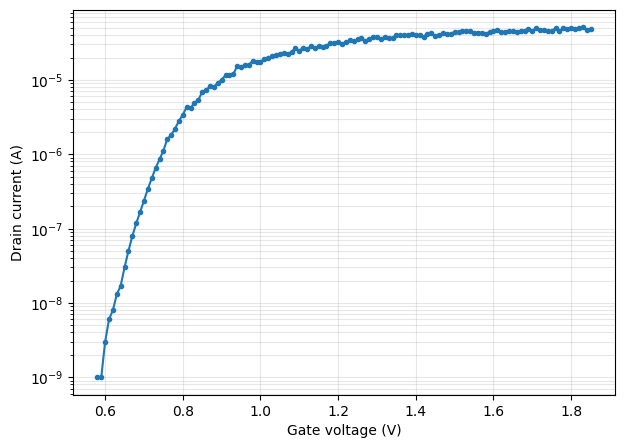

In [11]:
import matplotlib.pyplot as plt
positive = df.loc[df["Id"] > 0]
plt.figure(figsize=(7, 5))
plt.semilogy(positive["Vg_src"], positive["Id"], "o-", markersize=3)
plt.xlabel("Gate voltage (V)")
plt.ylabel("Drain current (A)")
plt.grid(True, which="both", alpha=0.3)
plt.show()


In [12]:
import numpy as np
from scipy.stats import linregress
sub = positive.loc[positive["Vg_src"].between(0.64, 0.74)]
fit = linregress(sub["Vg_src"], np.log10(sub["Id"]))
print("拟合点数：", len(sub))
print("斜率：", fit.slope, "dec/V")
print("R²：", fit.rvalue**2)
print("SS：", 1000 / fit.slope, "mV/dec")

拟合点数： 11
斜率： 16.687009017362936 dec/V
R²： 0.9898771749952797
SS： 59.92685681175661 mV/dec


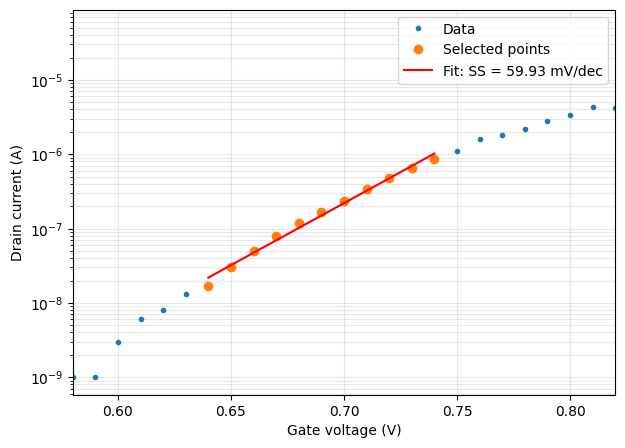

In [13]:
plt.figure(figsize=(7, 5))
plt.semilogy(positive["Vg_src"], positive["Id"], ".", label="Data")
plt.semilogy(sub["Vg_src"], sub["Id"], "o", label="Selected points")
predicted = 10**(fit.slope * sub["Vg_src"] + fit.intercept)
plt.semilogy(sub["Vg_src"], predicted, "r-", label=f"Fit: SS = {1000 / fit.slope:.2f} mV/dec")
plt.xlim(0.58, 0.82)
plt.xlabel("Gate voltage (V)")
plt.ylabel("Drain current (A)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

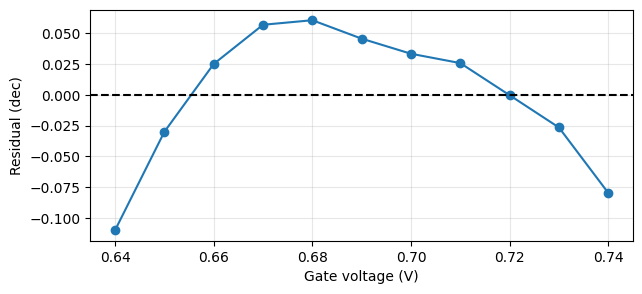

In [14]:
residual = np.log10(sub["Id"]) - (fit.slope * sub["Vg_src"] + fit.intercept)
plt.figure(figsize=(7, 3))
plt.plot(sub["Vg_src"], residual, "o-")
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Gate voltage (V)")
plt.ylabel("Residual (dec)")
plt.grid(True, alpha=0.3)
plt.show()

In [15]:
windows = [(0.64, 0.70), (0.66, 0.72), (0.68, 0.74), (0.64, 0.74)]
rows = []
for lo, hi in windows:
    s = positive.loc[positive["Vg_src"].between(lo, hi)]
    r = linregress(s["Vg_src"], np.log10(s["Id"]))
    span = np.log10(s["Id"].max() / s["Id"].min())
    rows.append([lo, hi, len(s), 1000 / r.slope, r.rvalue**2, span])
pd.DataFrame(rows, columns=["Vmin", "Vmax", "Points", "SS_mV_dec", "R2", "Current_span_dec"])

,Vmin,Vmax,Points,SS_mV_dec,R2,Current_span_dec
0,0.64,0.70,7,52.949197,0.990917,1.144299
1,0.66,0.72,7,62.125115,0.997668,0.975891
2,0.68,0.74,7,68.715850,0.997852,0.861233
3,0.64,0.74,11,59.926857,0.989877,1.698970


分析 UTA 团队公开的 SKY130 nMOS 77 K 测量数据。器件尺寸为 L = 0.15 μm、W = 1.6 μm，VDS = 0.01 V，源极和体端接地。在 VGS = 0.64–0.74 V 区间拟合得到平均 SS = 59.93 mV/dec，R² = 0.98988。邻近区间结果为 52.95–68.72 mV/dec，存在明显的区间依赖。低电流数据的舍入或仪器分辨率影响尚待确认。

In [16]:
url = "https://raw.githubusercontent.com/UTA-Advanced-Detector-Technologies/Skywater-130nm-77K-Cryogenic-Models/main/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd0p37.csv"
df_037 = pd.read_csv(url, skipinitialspace=True)

In [17]:
df_037.head()

,Vd_src,Vg_src,Id,Ig
0,0.37,0.00,0.0,0.0
1,0.37,0.01,0.0,0.0
2,0.37,0.02,0.0,0.0
3,0.37,0.03,0.0,0.0
4,0.37,0.04,0.0,0.0


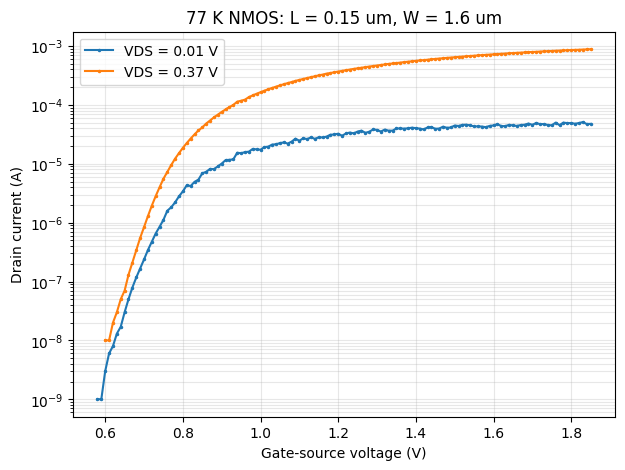

In [18]:
positive_037 = df_037.loc[df_037["Id"] > 0]
plt.figure(figsize=(7, 5))
plt.semilogy(positive["Vg_src"], positive["Id"], ".-", markersize=3, label="VDS = 0.01 V")
plt.semilogy(positive_037["Vg_src"], positive_037["Id"], ".-", markersize=3, label="VDS = 0.37 V")
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Drain current (A)")
plt.title("77 K NMOS: L = 0.15 um, W = 1.6 um")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

In [20]:
target = 1e-7
a = positive.sort_values("Vg_src")
b = positive_037.sort_values("Vg_src")
assert a["Id"].is_monotonic_increasing and b["Id"].is_monotonic_increasing, "电流非单调，需要先选取局部区间"
assert a["Id"].min() <= target <= a["Id"].max()
assert b["Id"].min() <= target <= b["Id"].max()
vg_001 = np.interp(np.log10(target), np.log10(a["Id"]), a["Vg_src"])
vg_037 = np.interp(np.log10(target), np.log10(b["Id"]), b["Vg_src"])
print("0.01 V 漏压对应的栅压：", vg_001, "V")
print("0.37 V 漏压对应的栅压：", vg_037, "V")
print("栅压位移：", (vg_001 - vg_037) * 1000, "mV")

AssertionError: 电流非单调，需要先选取局部区间

In [21]:
target = 1e-7
a = positive.loc[positive["Vg_src"].between(0.64, 0.70)].sort_values("Vg_src")
b = positive_037.loc[positive_037["Vg_src"].between(0.60, 0.72)].sort_values("Vg_src")
assert len(a) >= 2 and len(b) >= 2, "区间内数据不足"
assert (np.diff(a["Id"]) > 0).all() and (np.diff(b["Id"]) > 0).all(), "局部电流仍非严格递增，请发来这两段数据"
assert a["Id"].min() <= target <= a["Id"].max(), "0.01 V 曲线的区间未包含目标电流"
assert b["Id"].min() <= target <= b["Id"].max(), "0.37 V 曲线的区间未包含目标电流"
vg_001 = np.interp(np.log10(target), np.log10(a["Id"]), a["Vg_src"])
vg_037 = np.interp(np.log10(target), np.log10(b["Id"]), b["Vg_src"])
print("0.01 V 漏压对应的栅压：", vg_001, "V")
print("0.37 V 漏压对应的栅压：", vg_037, "V")
print("栅压位移：", (vg_001 - vg_037) * 1000, "mV")

AssertionError: 局部电流仍非严格递增，请发来这两段数据

In [23]:
print("VDS = 0.01 V\n", a[["Vg_src", "Id"]].to_string(index=False))
print("VDS = 0.37 V\n", b[["Vg_src", "Id"]].to_string(index=False))

VDS = 0.01 V
  Vg_src           Id
   0.64 1.700000e-08
   0.65 3.000000e-08
   0.66 5.000000e-08
   0.67 7.900000e-08
   0.68 1.170000e-07
   0.69 1.660000e-07
   0.70 2.370000e-07
VDS = 0.37 V
  Vg_src           Id
   0.60 1.000000e-08
   0.61 1.000000e-08
   0.62 2.000000e-08
   0.63 3.000000e-08
   0.64 5.000000e-08
   0.65 7.000000e-08
   0.66 1.300000e-07
   0.67 2.100000e-07
   0.68 3.400000e-07
   0.69 5.500000e-07
   0.70 8.400000e-07
   0.71 1.290000e-06
   0.72 1.940000e-06


In [24]:
vg_001 = np.interp(np.log10(1e-7), np.log10([79e-9, 117e-9]), [0.67, 0.68])
vg_037 = np.interp(np.log10(1e-7), np.log10([70e-9, 130e-9]), [0.65, 0.66])
print(f"VDS=0.01 V：VGS={vg_001:.6f} V；VDS=0.37 V：VGS={vg_037:.6f} V")
print(f"恒定电流下的栅压位移：{1000 * (vg_001 - vg_037):.2f} mV")

VDS=0.01 V：VGS=0.676002 V；VDS=0.37 V：VGS=0.655762 V
恒定电流下的栅压位移：20.24 mV


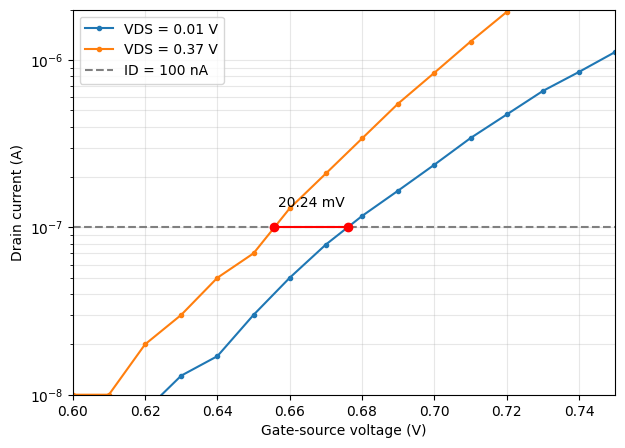

In [25]:
plt.figure(figsize=(7, 5))
plt.semilogy(positive["Vg_src"], positive["Id"], ".-", label="VDS = 0.01 V")
plt.semilogy(positive_037["Vg_src"], positive_037["Id"], ".-", label="VDS = 0.37 V")
plt.axhline(1e-7, color="gray", linestyle="--", label="ID = 100 nA")
plt.plot([vg_037, vg_001], [1e-7, 1e-7], "ro-")
plt.annotate(f"{1000*(vg_001-vg_037):.2f} mV", xy=((vg_001+vg_037)/2, 1e-7), xytext=(0, 15), textcoords="offset points", ha="center")
plt.xlim(0.60, 0.75)
plt.ylim(1e-8, 2e-6)
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Drain current (A)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

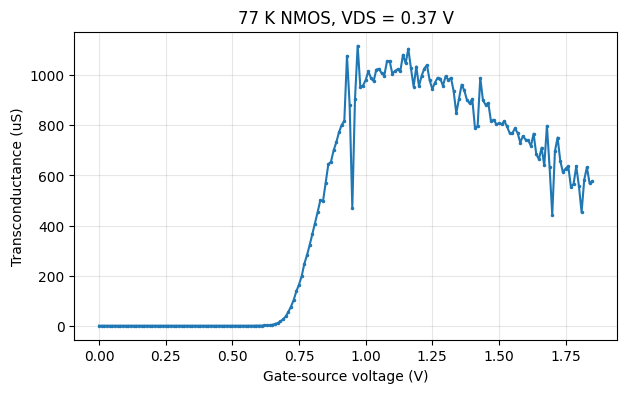

In [26]:
d037 = df_037.sort_values("Vg_src").copy()
vg = d037["Vg_src"].to_numpy()
current = d037["Id"].to_numpy()
assert np.all(np.diff(vg) > 0), "栅压有重复点，需要先检查"
gm = np.gradient(current, vg)
plt.figure(figsize=(7, 4))
plt.plot(vg, gm * 1e6, ".-", markersize=3)
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Transconductance (uS)")
plt.title("77 K NMOS, VDS = 0.37 V")
plt.grid(True, alpha=0.3)
plt.show()

候选 Vth： 0.7801017699115044 V
R²： 0.933276170185443


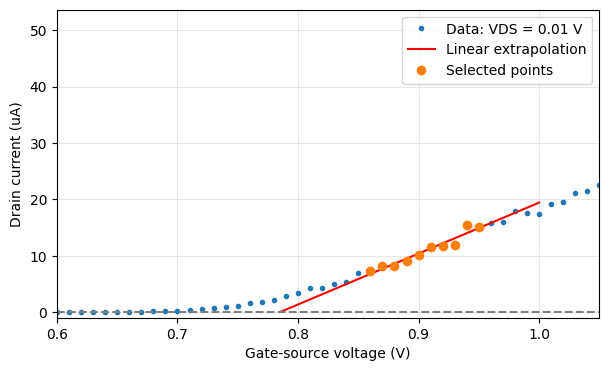

In [27]:
vt_data = df.loc[df["Vg_src"].between(0.85, 0.95)].sort_values("Vg_src")
vt_fit = linregress(vt_data["Vg_src"], vt_data["Id"])
v_intercept = -vt_fit.intercept / vt_fit.slope
print("候选 Vth：", v_intercept - 0.01 / 2, "V")
print("R²：", vt_fit.rvalue**2)
xx = np.linspace(min(v_intercept, 0.85), 1.00, 100)
plt.figure(figsize=(7, 4))
plt.plot(df["Vg_src"], df["Id"] * 1e6, ".", label="Data: VDS = 0.01 V")
plt.plot(xx, (vt_fit.slope * xx + vt_fit.intercept) * 1e6, "r-", label="Linear extrapolation")
plt.plot(vt_data["Vg_src"], vt_data["Id"] * 1e6, "o", label="Selected points")
plt.axhline(0, color="gray", linestyle="--")
plt.xlim(0.60, 1.05)
plt.ylim(bottom=-1)
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Drain current (uA)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [28]:
windows_vt = [(0.80, 0.90), (0.85, 0.95), (0.90, 1.00)]
rows_vt = []
for lo, hi in windows_vt:
    s = df.loc[df["Vg_src"].between(lo, hi)]
    r = linregress(s["Vg_src"], s["Id"])
    rows_vt.append([lo, hi, len(s), -r.intercept / r.slope - 0.005, r.rvalue**2])
pd.DataFrame(rows_vt, columns=["Vmin", "Vmax", "Points", "Vth_V", "R2"])

,Vmin,Vmax,Points,Vth_V,R2
0,0.80,0.90,11,0.745992,0.976455
1,0.85,0.95,10,0.780102,0.933276
2,0.90,1.00,11,0.762312,0.906060


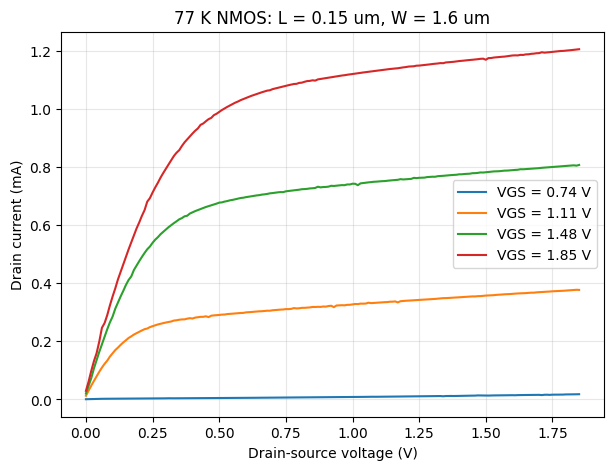

In [29]:
base = url.rsplit("/", 1)[0]
plt.figure(figsize=(7, 5))
for tag in ["0p74", "1p11", "1p48", "1p85"]:
    out = pd.read_csv(base + "/idvd_Vg" + tag + ".csv", skipinitialspace=True).sort_values("Vd_src")
    plt.plot(out["Vd_src"], out["Id"] * 1e3, label="VGS = " + tag.replace("p", ".") + " V")
plt.xlabel("Drain-source voltage (V)")
plt.ylabel("Drain current (mA)")
plt.title("77 K NMOS: L = 0.15 um, W = 1.6 um")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [30]:
plt.savefig("77K_NMOS_output_curves.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

本阶段分析了公开的 SKY130 nMOS 77 K 测量数据，器件尺寸为 L = 0.15 μm、W = 1.6 μm。
在 VDS = 0.01 V、VGS = 0.64–0.74 V 区间，平均 SS 为 59.93 mV/dec；邻近区间结果为 52.95–68.72 mV/dec，存在区间依赖。
在 ID = 100 nA 时，VDS 从 0.01 V 增至 0.37 V，对应栅压降低 20.24 mV。
已绘制 VDS = 0.37 V 的跨导曲线，求导结果存在波动。低漏压线性外推得到候选阈值 0.746–0.780 V，尚未确定唯一值。
已绘制四种栅压下的输出特性，较高漏压区仍存在非零输出斜率。以上属于数据分析结果，尚未完成模型建立与验证。

In [31]:
vt_data = df.loc[df["Vg_src"].between(0.85, 0.95)]
vt_fit = linregress(vt_data["Vg_src"], vt_data["Id"])
beta_initial = vt_fit.slope / 0.01
vth_initial = -vt_fit.intercept / vt_fit.slope - 0.005
print(f"初始 beta = {beta_initial:.6e} A/V²")
print(f"初始 Vth = {vth_initial:.4f} V")

初始 beta = 9.040000e-03 A/V²
初始 Vth = 0.7801 V


In [32]:
import pandas as pd
from scipy.stats import linregress
url_001 = "https://raw.githubusercontent.com/UTA-Advanced-Detector-Technologies/Skywater-130nm-77K-Cryogenic-Models/main/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd0p01.csv"
df = pd.read_csv(url_001, skipinitialspace=True)

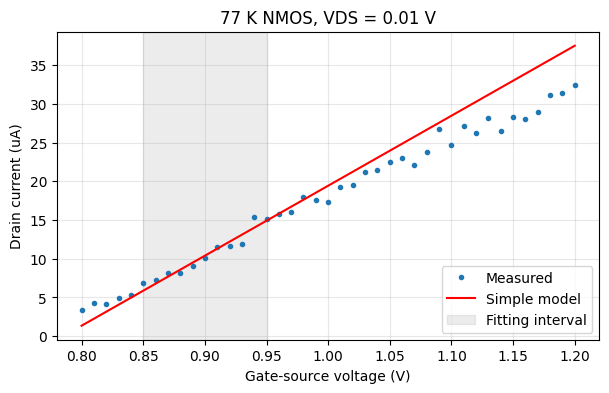

In [33]:
import numpy as np
import matplotlib.pyplot as plt
check = df.loc[df["Vg_src"].between(0.80, 1.20)].sort_values("Vg_src").copy()
check["Id_model"] = beta_initial * 0.01 * (check["Vg_src"] - vth_initial - 0.005)
plt.figure(figsize=(7, 4))
plt.plot(check["Vg_src"], check["Id"] * 1e6, "o", markersize=3, label="Measured")
plt.plot(check["Vg_src"], check["Id_model"] * 1e6, "r-", label="Simple model")
plt.axvspan(0.85, 0.95, color="gray", alpha=0.15, label="Fitting interval")
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Drain current (uA)")
plt.title("77 K NMOS, VDS = 0.01 V")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [34]:
check["error_uA"] = (check["Id_model"] - check["Id"]) * 1e6
check["relative_error_pct"] = 100 * (check["Id_model"] - check["Id"]) / check["Id"]
train = check.loc[check["Vg_src"].between(0.85, 0.95)]
test = check.loc[check["Vg_src"] > 0.95]
print("拟合区间 RMSE：", np.sqrt(np.mean(train["error_uA"]**2)), "uA")
print("外推区间 RMSE：", np.sqrt(np.mean(test["error_uA"]**2)), "uA")
print("外推区间平均绝对相对误差：", test["relative_error_pct"].abs().mean(), "%")

拟合区间 RMSE： 0.6942738364651251 uA
外推区间 RMSE： 3.3577478928591438 uA
外推区间平均绝对相对误差： 10.862004397561543 %


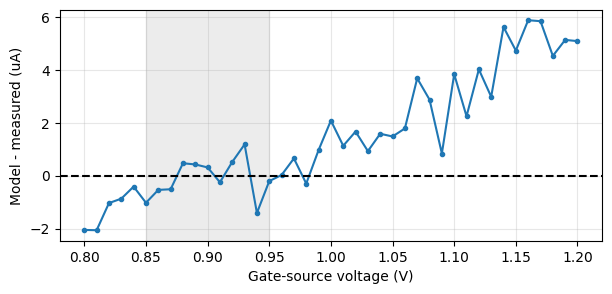

In [35]:
plt.figure(figsize=(7, 3))
plt.plot(check["Vg_src"], check["error_uA"], "o-", markersize=3)
plt.axhline(0, color="black", linestyle="--")
plt.axvspan(0.85, 0.95, color="gray", alpha=0.15)
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Model - measured (uA)")
plt.grid(True, alpha=0.3)
plt.show()

In [36]:
from scipy.optimize import curve_fit
def corrected_model(vg, beta0, v0, theta):
    overdrive = vg - v0
    return beta0 * 0.01 * (overdrive - 0.005) / (1 + theta * overdrive)
params, covariance = curve_fit(corrected_model, check["Vg_src"].to_numpy(), check["Id"].to_numpy() * 1e6, p0=[beta_initial * 1e6, vth_initial, 1.0], bounds=([0, 0.4, 0], [1e6, 0.79, 100]), maxfev=20000)
check["Id_corrected"] = corrected_model(check["Vg_src"], *params) * 1e-6
print(f"beta0 = {params[0] * 1e-6:.6e} A/V²；V0 = {params[1]:.4f} V；theta = {params[2]:.4f} 1/V")
print("修正模型 RMSE：", np.sqrt(np.mean(((check["Id_corrected"] - check["Id"]) * 1e6)**2)), "uA")
print("原模型同区间 RMSE：", np.sqrt(np.mean(check["error_uA"]**2)), "uA")

beta0 = 8.764433e-03 A/V²；V0 = 0.7655 V；theta = 0.4202 1/V
修正模型 RMSE： 0.8062602277671562 uA
原模型同区间 RMSE： 2.696868649595442 uA


In [38]:
plt.figure(figsize=(7, 4))
plt.plot(check["Vg_src"], check["Id"] * 1e6, "o", markersize=3, label="Measured")
plt.plot(check["Vg_src"], check["Id_model"] * 1e6, "--", label="Original model")
plt.plot(check["Vg_src"], check["Id_corrected"] * 1e6, "r-", label="Corrected model")
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Drain current (uA)")
plt.title("77 K NMOS, VDS = 0.01 V")
plt.grid(True, alpha=0.3)
plt.legend(
plt.show()

_IncompleteInputError: incomplete input (2444357900.py, line 10)

检查点数： 65
原模型 RMSE： 27.817889519073603 uA
修正模型 RMSE： 8.956164686561612 uA


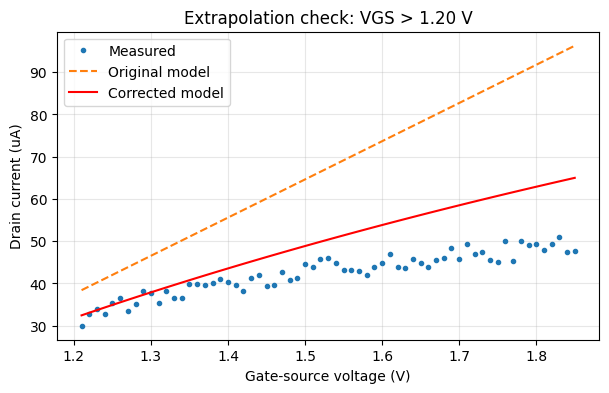

In [40]:
validation = df.loc[df["Vg_src"] > 1.20].sort_values("Vg_src").copy()
validation["original"] = beta_initial * 0.01 * (validation["Vg_src"] - vth_initial - 0.005)
validation["corrected"] = corrected_model(validation["Vg_src"], *params) * 1e-6
print("检查点数：", len(validation))
print("原模型 RMSE：", np.sqrt(np.mean(((validation["original"] - validation["Id"]) * 1e6)**2)), "uA")
print("修正模型 RMSE：", np.sqrt(np.mean(((validation["corrected"] - validation["Id"]) * 1e6)**2)), "uA")
plt.figure(figsize=(7, 4))
plt.plot(validation["Vg_src"], validation["Id"] * 1e6, ".", label="Measured")
plt.plot(validation["Vg_src"], validation["original"] * 1e6, "--", label="Original model")
plt.plot(validation["Vg_src"], validation["corrected"] * 1e6, "r-", label="Corrected model")
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Drain current (uA)")
plt.title("Extrapolation check: VGS > 1.20 V")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [41]:
!apt-get -qq update
!apt-get -qq install -y ngspice
!ngspice --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package ngspice.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../ngspice_42+ds-3build1_amd64.deb ...
Unpacking ngspice (42+ds-3build1) ...
Setting up ngspice (42+ds-3build1) ...
Processing triggers for man-db (2.12.0-4build2) ...
******
** ngspice-42 : Circuit level simulation program
** Compiled with KLU Direct Linear Solver
** The U. C. Berkeley CAD Group
** Copyright 1985-1994, Regents of the University of California.
** Copyright 2001-2023, The ngspice team.
** Please get your ngspice manual from https://ngspice.sourceforge.io/docs.html
** Please file your bug-reports at http://ngspice.sourceforge.net/bugrep.html
** Creation Date: Sun Mar 31 20:15:14 UTC 2024
******


In [42]:
import pathlib
import subprocess
repo = pathlib.Path("/content/sky130_77k")
if not repo.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/UTA-Advanced-Detector-Technologies/Skywater-130nm-77K-Cryogenic-Models.git", str(repo)], check=True)
print("模型目录中的文件：")
print("\n".join(str(p.relative_to(repo)) for p in sorted((repo / "models").rglob("*")) if p.is_file()))

模型目录中的文件：



In [43]:
print("仓库目录存在：", repo.exists())
print("仓库顶层内容：")
print("\n".join(p.name for p in sorted(repo.iterdir())))

仓库目录存在： True
仓库顶层内容：
.git
.gitignore
README.md
cryo_data
cryo_models


In [44]:
model_files = sorted(p for p in (repo / "cryo_models").rglob("*") if p.is_file())
print("\n".join(str(p.relative_to(repo)) for p in model_files))

cryo_models/sky130_fd_pr__nfet_01v8_lvt__tt_77k.corner.spice
cryo_models/sky130_fd_pr__pfet_01v8_lvt__tt_77k.corner.spice


In [45]:
nmos_path = repo / "cryo_models" / "sky130_fd_pr__nfet_01v8_lvt__tt_77k.corner.spice"
nmos_text = nmos_path.read_text()
print("文件前 60 行：")
print("\n".join(nmos_text.splitlines()[:60]))
print("\n模型、子电路及依赖声明：")
print("\n".join(line for line in nmos_text.splitlines() if line.strip().lower().startswith((".include", ".lib", ".subckt", ".model", ".ends"))))

文件前 60 行：
.include "./skywater-pdk/libraries/sky130_fd_pr/latest/models/parameters/lod.spice"
.param mc_mm_switch = 0
.param mc_pr_switch = 0
.option scale=1.0u
.param my_gauss = AGAUSS(0,1.0,1)
.param lv_dlc_rotweak = 0
.param lvhvt_dlc_rotweak = 0
.param lvt_dlc_rotweak = 0
.param hv_dlc_rotweak = 0
.param sky130_fd_pr__nfet_01v8__dlc_rotweak = lv_dlc_rotweak
.param sky130_fd_pr__esd_nfet_01v8__dlc_rotweak = lv_dlc_rotweak
.param sky130_fd_pr__nfet_01v8_lvt__dlc_rotweak = lvt_dlc_rotweak
.param sky130_fd_pr__pfet_01v8__dlc_rotweak = lv_dlc_rotweak
.param sky130_fd_pr__pfet_01v8_lvt__dlc_rotweak = lvt_dlc_rotweak
.param sky130_fd_pr__pfet_01v8_hvt__dlc_rotweak = lvhvt_dlc_rotweak
.param sky130_fd_pr__esd_nfet_g5v0d10v5__dlc_rotweak = hv_dlc_rotweak
.param sky130_fd_pr__esd_pfet_g5v0d10v5__dlc_rotweak = hv_dlc_rotweak
.param sky130_fd_pr__nfet_03v3_nvt__dlc_rotweak = hv_dlc_rotweak
.param sky130_fd_pr__nfet_05v0_nvt__dlc_rotweak = hv_dlc_rotweak
.param sky130_fd_pr__nfet_g5v0d10v5__dlc

In [46]:
nmos_path = repo / "cryo_models" / "sky130_fd_pr__nfet_01v8_lvt__tt_77k.corner.spice"
nmos_text = nmos_path.read_text()
print("文件前 60 行：")
print("\n".join(nmos_text.splitlines()[:60]))
print("\n模型、子电路及依赖声明：")
print("\n".join(line for line in nmos_text.splitlines() if line.strip().lower().startswith((".include", ".lib", ".subckt", ".model", ".ends"))))

文件前 60 行：
.include "./skywater-pdk/libraries/sky130_fd_pr/latest/models/parameters/lod.spice"
.param mc_mm_switch = 0
.param mc_pr_switch = 0
.option scale=1.0u
.param my_gauss = AGAUSS(0,1.0,1)
.param lv_dlc_rotweak = 0
.param lvhvt_dlc_rotweak = 0
.param lvt_dlc_rotweak = 0
.param hv_dlc_rotweak = 0
.param sky130_fd_pr__nfet_01v8__dlc_rotweak = lv_dlc_rotweak
.param sky130_fd_pr__esd_nfet_01v8__dlc_rotweak = lv_dlc_rotweak
.param sky130_fd_pr__nfet_01v8_lvt__dlc_rotweak = lvt_dlc_rotweak
.param sky130_fd_pr__pfet_01v8__dlc_rotweak = lv_dlc_rotweak
.param sky130_fd_pr__pfet_01v8_lvt__dlc_rotweak = lvt_dlc_rotweak
.param sky130_fd_pr__pfet_01v8_hvt__dlc_rotweak = lvhvt_dlc_rotweak
.param sky130_fd_pr__esd_nfet_g5v0d10v5__dlc_rotweak = hv_dlc_rotweak
.param sky130_fd_pr__esd_pfet_g5v0d10v5__dlc_rotweak = hv_dlc_rotweak
.param sky130_fd_pr__nfet_03v3_nvt__dlc_rotweak = hv_dlc_rotweak
.param sky130_fd_pr__nfet_05v0_nvt__dlc_rotweak = hv_dlc_rotweak
.param sky130_fd_pr__nfet_g5v0d10v5__dlc

In [49]:
import urllib.request
lod_path = repo / "skywater-pdk/libraries/sky130_fd_pr/latest/models/parameters/lod.spice"
lod_path.parent.mkdir(parents=True, exist_ok=True)
lod_url = "https://raw.githubusercontent.com/google/skywater-pdk-libs-sky130_fd_pr/main/models/parameters/lod.spice"
urllib.request.urlretrieve(lod_url, lod_path)
print("依赖文件已下载：", lod_path)
print("\n".join(lod_path.read_text().splitlines()[:15])))

SyntaxError: unmatched ')' (3805931696.py, line 7)

In [51]:
import pathlib
import urllib.request
repo = pathlib.Path("/content/sky130_77k")
lod_path = repo / "skywater-pdk/libraries/sky130_fd_pr/latest/models/parameters/lod.spice"
lod_path.parent.mkdir(parents=True, exist_ok=True)
lod_url = "https://raw.githubusercontent.com/google/skywater-pdk-libs-sky130_fd_pr/main/models/parameters/lod.spice"
urllib.request.urlretrieve(lod_url, lod_path)
print("依赖文件已下载：", lod_path)
print("\n".join(lod_path.read_text().splitlines()[:15]))

依赖文件已下载： /content/sky130_77k/skywater-pdk/libraries/sky130_fd_pr/latest/models/parameters/lod.spice
* SKY130 Spice File.
.param
+ sky130_fd_pr__nfet_01v8_lvt__lkvth0_diff = 0.0
+ sky130_fd_pr__nfet_01v8_lvt__wlod_diff = 0.0
+ sky130_fd_pr__nfet_01v8_lvt__lku0_diff = 0.0
+ sky130_fd_pr__nfet_01v8_lvt__kvth0_diff = 7.9e-9
+ sky130_fd_pr__nfet_01v8_lvt__wkvth0_diff = .3e-6
+ sky130_fd_pr__nfet_01v8_lvt__ku0_diff = -2.7e-8
+ sky130_fd_pr__nfet_01v8_lvt__wku0_diff = 0.0
+ sky130_fd_pr__nfet_01v8_lvt__kvsat_diff = 0.2
+ sky130_fd_pr__pfet_01v8__lkvth0_diff = .0e-6
+ sky130_fd_pr__pfet_01v8__wlod_diff = .0e-6
+ sky130_fd_pr__pfet_01v8__lku0_diff = 0.0
+ sky130_fd_pr__pfet_01v8__kvsat_diff = 0.5
+ sky130_fd_pr__pfet_01v8__kvth0_diff = 3.29e-8


In [52]:
import subprocess
netlist = "\n".join(["77 K NMOS transfer curve", '.include "cryo_models/sky130_fd_pr__nfet_01v8_lvt__tt_77k.corner.spice"', ".temp -196.15", "VD d 0 0.01", "VG g 0 0", "X1 d g 0 0 sky130_fd_pr__nfet_01v8_lvt l=0.15 w=1.6", ".control", "set wr_singlescale", "set wr_vecnames", "dc VG 0 1.85 0.01", "let idrain = -i(VD)", "wrdata idvg_bsim4_77k.txt v(g) idrain", "quit", ".endc", ".end", ""])
circuit_path = repo / "nmos_77k_test.cir"
circuit_path.write_text(netlist)
result = subprocess.run(["ngspice", "-b", circuit_path.name], cwd=str(repo), capture_output=True, text=True)
print("退出码：", result.returncode)
print(result.stdout)
print(result.stderr)
print("结果文件存在：", (repo / "idvg_bsim4_77k.txt").exists())


退出码： 0

Note: No compatibility mode selected!


Circuit: 77 k nmos transfer curve

Doing analysis at TEMP = -196.150000 and TNOM = 27.000000

 Reference value :  3.20000e-01
No. of Data Rows : 186
ngspice-42 done

Using SPARSE 1.3 as Direct Linear Solver

结果文件存在： True


结果前五行：
 [[0.00000000e+00 0.00000000e+00 1.00000004e-14]
 [1.00000000e-02 1.00000000e-02 1.00000006e-14]
 [2.00000000e-02 2.00000000e-02 1.00000011e-14]
 [3.00000000e-02 3.00000000e-02 1.00000018e-14]
 [4.00000000e-02 4.00000000e-02 1.00000030e-14]]


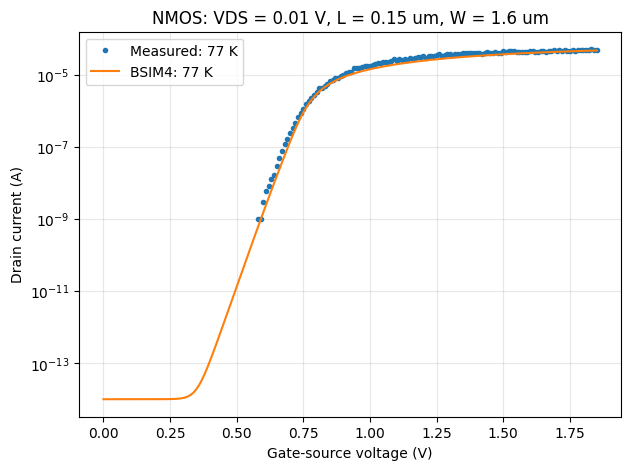

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sim = np.loadtxt(repo / "idvg_bsim4_77k.txt", skiprows=1)
print("结果前五行：\n", sim[:5])
measured = pd.read_csv(repo / "cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd0p01.csv", skipinitialspace=True)
plt.figure(figsize=(7, 5))
plt.semilogy(measured.loc[measured["Id"] > 0, "Vg_src"], measured.loc[measured["Id"] > 0, "Id"], ".", label="Measured: 77 K")
plt.semilogy(sim[sim[:, -1] > 0, 1], sim[sim[:, -1] > 0, -1], "-", label="BSIM4: 77 K")
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Drain current (A)")
plt.title("NMOS: VDS = 0.01 V, L = 0.15 um, W = 1.6 um")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

In [54]:
comparison = measured.sort_values("Vg_src").copy()
comparison["Id_sim"] = np.interp(comparison["Vg_src"], sim[:, 1], sim[:, -1])
on = comparison.loc[comparison["Id"] >= 1e-6].copy()
sub_check = comparison.loc[(comparison["Id"] >= 1e-8) & (comparison["Id"] <= 1e-6)].copy()
print("ID ≥ 1 uA 的点数：", len(on))
print("该区间电流 RMSE：", np.sqrt(np.mean((on["Id_sim"] - on["Id"])**2)) * 1e6, "uA")
print("该区间平均绝对相对误差：", (100 * abs(on["Id_sim"] - on["Id"]) / on["Id"]).mean(), "%")
print("10 nA–1 uA 区间点数：", len(sub_check))
print("该区间对数 RMSE：", np.sqrt(np.mean(np.log10(sub_check["Id_sim"] / sub_check["Id"])**2)), "dec")

ID ≥ 1 uA 的点数： 111
该区间电流 RMSE： 5.130037673101928 uA
该区间平均绝对相对误差： 15.405065747633287 %
10 nA–1 uA 区间点数： 12
该区间对数 RMSE： 0.2560306297973614 dec



Note: No compatibility mode selected!


Circuit: 77 k nmos transfer curve

Doing analysis at TEMP = -196.150000 and TNOM = 27.000000


No. of Data Rows : 186
ngspice-42 done
 Using SPARSE 1.3 as Direct Linear Solver



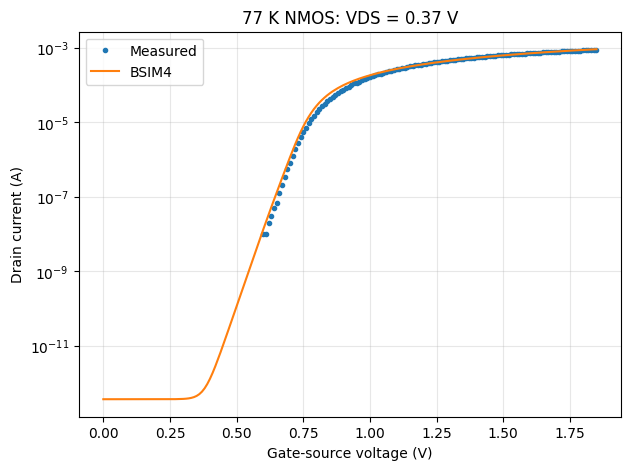

In [55]:
netlist_037 = netlist.replace("VD d 0 0.01", "VD d 0 0.37").replace("idvg_bsim4_77k.txt", "idvg_bsim4_77k_vd037.txt")
path_037 = repo / "nmos_77k_vd037.cir"
path_037.write_text(netlist_037)
run_037 = subprocess.run(["ngspice", "-b", path_037.name], cwd=str(repo), capture_output=True, text=True)
print(run_037.stdout, run_037.stderr)
assert run_037.returncode == 0, "仿真失败，请检查上面的日志"
sim_037 = np.loadtxt(repo / "idvg_bsim4_77k_vd037.txt", skiprows=1)
meas_037 = pd.read_csv(repo / "cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd0p37.csv", skipinitialspace=True)
plt.figure(figsize=(7, 5))
plt.semilogy(meas_037.loc[meas_037["Id"] > 0, "Vg_src"], meas_037.loc[meas_037["Id"] > 0, "Id"], ".", label="Measured")
plt.semilogy(sim_037[sim_037[:, -1] > 0, 1], sim_037[sim_037[:, -1] > 0, -1], "-", label="BSIM4")
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Drain current (A)")
plt.title("77 K NMOS: VDS = 0.37 V")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

In [56]:
comparison_037 = meas_037.sort_values("Vg_src").copy()
comparison_037["Id_sim"] = np.interp(comparison_037["Vg_src"], sim_037[:, 1], sim_037[:, -1])
on_037 = comparison_037.loc[comparison_037["Id"] >= 1e-6].copy()
sub_037 = comparison_037.loc[(comparison_037["Id"] >= 1e-8) & (comparison_037["Id"] <= 1e-6)].copy()
print("ID ≥ 1 uA 的点数：", len(on_037))
print("电流 RMSE：", np.sqrt(np.mean((on_037["Id_sim"] - on_037["Id"])**2)) * 1e6, "uA")
print("平均绝对相对误差：", (100 * abs(on_037["Id_sim"] - on_037["Id"]) / on_037["Id"]).mean(), "%")
print("10 nA–1 uA 区间点数：", len(sub_037))
print("对数 RMSE：", np.sqrt(np.mean(np.log10(sub_037["Id_sim"] / sub_037["Id"])**2)), "dec")

ID ≥ 1 uA 的点数： 115
电流 RMSE： 15.95262793472494 uA
平均绝对相对误差： 10.97344817340895 %
10 nA–1 uA 区间点数： 11
对数 RMSE： 0.20825295239156813 dec



Note: No compatibility mode selected!


Circuit: 77 k nmos transfer curve

Doing analysis at TEMP = -196.150000 and TNOM = 27.000000


No. of Data Rows : 186
ngspice-42 done
 Using SPARSE 1.3 as Direct Linear Solver



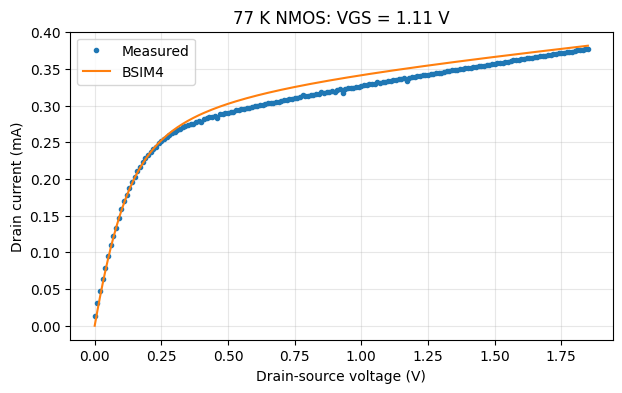

In [57]:
output_netlist = netlist.replace("VD d 0 0.01", "VD d 0 0").replace("VG g 0 0", "VG g 0 1.11").replace("dc VG 0 1.85 0.01", "dc VD 0 1.85 0.01").replace("wrdata idvg_bsim4_77k.txt v(g) idrain", "wrdata idvd_bsim4_77k_vg111.txt v(d) idrain")
output_path = repo / "nmos_output_vg111.cir"
output_path.write_text(output_netlist)
output_run = subprocess.run(["ngspice", "-b", output_path.name], cwd=str(repo), capture_output=True, text=True)
print(output_run.stdout, output_run.stderr)
assert output_run.returncode == 0, "仿真失败，请检查日志"
sim_out = np.loadtxt(repo / "idvd_bsim4_77k_vg111.txt", skiprows=1)
meas_out = pd.read_csv(repo / "cryo_data/nmos_FET_len_0p15_wid_1p6/idvd_Vg1p11.csv", skipinitialspace=True)
plt.figure(figsize=(7, 4))
plt.plot(meas_out["Vd_src"], meas_out["Id"] * 1e3, ".", label="Measured")
plt.plot(sim_out[:, 1], sim_out[:, -1] * 1e3, "-", label="BSIM4")
plt.xlabel("Drain-source voltage (V)")
plt.ylabel("Drain current (mA)")
plt.title("77 K NMOS: VGS = 1.11 V")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [58]:
out_compare = meas_out.sort_values("Vd_src").copy()
out_compare["Id_sim"] = np.interp(out_compare["Vd_src"], sim_out[:, 1], sim_out[:, -1])
out_eval = out_compare.loc[(out_compare["Vd_src"] >= 0.05) & (out_compare["Vd_src"] <= 1.85) & (out_compare["Id"] > 0)].copy()
print("比较点数：", len(out_eval))
print("输出曲线 RMSE：", np.sqrt(np.mean((out_eval["Id_sim"] - out_eval["Id"])**2)) * 1e6, "uA")
print("平均绝对相对误差：", (100 * abs(out_eval["Id_sim"] - out_eval["Id"]) / out_eval["Id"]).mean(), "%")

比较点数： 181
输出曲线 RMSE： 10.972841094521886 uA
平均绝对相对误差： 3.1298652417084036 %


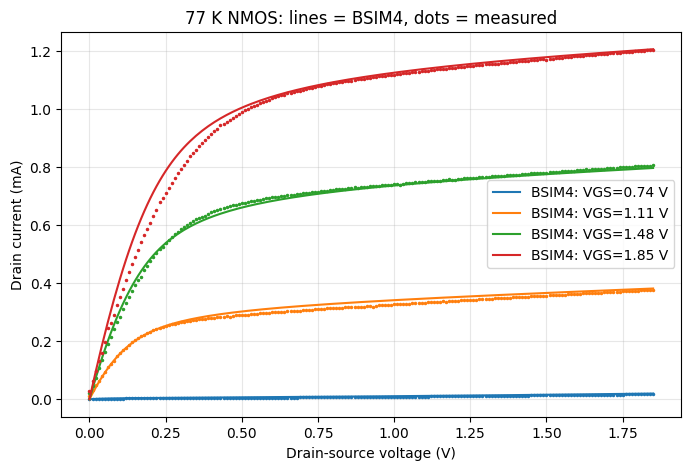

,VGS_V,Points,RMSE_uA,MAPE_pct
0,0.74,181,1.864986,25.918395
1,1.11,181,10.972841,3.129865
2,1.48,181,9.093216,1.357418
3,1.85,181,29.662386,2.728116


In [59]:
output_rows = []
plt.figure(figsize=(8, 5))
for tag in ["0p74", "1p11", "1p48", "1p85"]:
    vg_value = float(tag.replace("p", "."))
    text = output_netlist.replace("VG g 0 1.11", f"VG g 0 {vg_value}").replace("idvd_bsim4_77k_vg111.txt", f"idvd_{tag}.txt")
    path = repo / f"output_{tag}.cir"
    path.write_text(text)
    run = subprocess.run(["ngspice", "-b", path.name], cwd=str(repo), capture_output=True, text=True)
    assert run.returncode == 0, run.stdout + run.stderr
    s = np.loadtxt(repo / f"idvd_{tag}.txt", skiprows=1)
    m = pd.read_csv(repo / f"cryo_data/nmos_FET_len_0p15_wid_1p6/idvd_Vg{tag}.csv", skipinitialspace=True).sort_values("Vd_src")
    prediction = np.interp(m["Vd_src"], s[:, 1], s[:, -1])
    mask = m["Vd_src"].between(0.05, 1.85) & (m["Id"] > 0)
    error = prediction[mask] - m.loc[mask, "Id"]
    output_rows.append([vg_value, int(mask.sum()), np.sqrt(np.mean(error**2)) * 1e6, (100 * abs(error) / m.loc[mask, "Id"]).mean()])
    line, = plt.plot(s[:, 1], s[:, -1] * 1e3, label=f"BSIM4: VGS={vg_value} V")
    plt.plot(m["Vd_src"], m["Id"] * 1e3, ".", color=line.get_color(), markersize=3)
plt.xlabel("Drain-source voltage (V)")
plt.ylabel("Drain current (mA)")
plt.title("77 K NMOS: lines = BSIM4, dots = measured")
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig(repo / "77K_BSIM4_output_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
output_summary = pd.DataFrame(output_rows, columns=["VGS_V", "Points", "RMSE_uA", "MAPE_pct"])
display(output_summary)

In [60]:
from google.colab import files
files.download(str(repo / "77K_BSIM4_output_comparison.png"))
files.download(str(repo / "77K_BSIM4_output_errors.csv"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FileNotFoundError: Cannot find file: /content/sky130_77k/77K_BSIM4_output_errors.csv

In [62]:
data_dir = repo / "cryo_data" / "nmos_FET_len_0p15_wid_1p6"
data_files = sorted(data_dir.glob("*.csv"))
print("器件：nMOS；L=0.15 um；W=1.6 um；温度=77 K")
print("CSV 数量：", len(data_files))
print("\n".join(p.name for p in data_files))

器件：nMOS；L=0.15 um；W=1.6 um；温度=77 K
CSV 数量： 11
idvd_Vg0p37.csv
idvd_Vg0p74.csv
idvd_Vg1p11.csv
idvd_Vg1p48.csv
idvd_Vg1p85.csv
idvg_Vd0p01.csv
idvg_Vd0p37.csv
idvg_Vd0p74.csv
idvg_Vd1p11.csv
idvg_Vd1p48.csv
idvg_Vd1p85.csv


In [63]:
fit_files = {"idvg_Vd0p01.csv", "idvg_Vd0p37.csv", "idvd_Vg0p74.csv", "idvd_Vg1p11.csv", "idvd_Vg1p85.csv"}
inventory_rows = []
for p in data_files:
    d = pd.read_csv(p, skipinitialspace=True)
    sweep = "Vg_src" if p.name.startswith("idvg") else "Vd_src"
    fixed = "Vd_src" if sweep == "Vg_src" else "Vg_src"
    role = "fit" if p.name in fit_files else "check"
    inventory_rows.append([p.name, role, 77, 0.15, 1.6, len(d), fixed, d[fixed].min(), d[fixed].max(), sweep, d[sweep].min(), d[sweep].max(), int(d.isna().sum().sum()), int(d[sweep].duplicated().sum()), int((d["Id"] <= 0).sum())])
inventory = pd.DataFrame(inventory_rows, columns=["file", "role", "T_K", "L_um", "W_um", "points", "fixed_column", "fixed_min_V", "fixed_max_V", "sweep_column", "sweep_min_V", "sweep_max_V", "missing_values", "duplicate_sweep", "nonpositive_Id"])
display(inventory)
inventory.to_csv(repo / "data_inventory.csv", index=False)

,file,role,T_K,L_um,W_um,points,fixed_column,fixed_min_V,fixed_max_V,sweep_column,sweep_min_V,sweep_max_V,missing_values,duplicate_sweep,nonpositive_Id
0,idvd_Vg0p37.csv,check,77,0.15,1.6,186,Vg_src,0.37,0.37,Vd_src,0.0,1.85,0,0,186
1,idvd_Vg0p74.csv,fit,77,0.15,1.6,186,Vg_src,0.74,0.74,Vd_src,0.0,1.85,0,0,0
2,idvd_Vg1p11.csv,fit,77,0.15,1.6,186,Vg_src,1.11,1.11,Vd_src,0.0,1.85,0,0,0
3,idvd_Vg1p48.csv,check,77,0.15,1.6,186,Vg_src,1.48,1.48,Vd_src,0.0,1.85,0,0,0
4,idvd_Vg1p85.csv,fit,77,0.15,1.6,186,Vg_src,1.85,1.85,Vd_src,0.0,1.85,0,0,0
5,idvg_Vd0p01.csv,fit,77,0.15,1.6,186,Vd_src,0.01,0.01,Vg_src,0.0,1.85,0,0,58
6,idvg_Vd0p37.csv,fit,77,0.15,1.6,186,Vd_src,0.37,0.37,Vg_src,0.0,1.85,0,0,60
7,idvg_Vd0p74.csv,check,77,0.15,1.6,186,Vd_src,0.74,0.74,Vg_src,0.0,1.85,0,0,63
8,idvg_Vd1p11.csv,check,77,0.15,1.6,186,Vd_src,1.11,1.11,Vg_src,0.0,1.85,0,0,62
9,idvg_Vd1p48.csv,check,77,0.15,1.6,186,Vd_src,1.48,1.48,Vg_src,0.0,1.85,0,0,60


In [64]:
inventory.loc[inventory["file"] == "idvd_Vg0p37.csv", "role"] = "low_current_review"
inventory.to_csv(repo / "data_inventory.csv", index=False)

In [65]:
iref = 100e-9 * 1.6 / 0.15
d_cc = pd.read_csv(data_dir / "idvg_Vd0p01.csv", skipinitialspace=True).sort_values("Vg_src")
print("参考电流：", iref * 1e6, "uA")
print(d_cc.loc[d_cc["Id"].between(0.5 * iref, 2 * iref), ["Vg_src", "Id"]].to_string(index=False))

参考电流： 1.0666666666666667 uA
 Vg_src           Id
   0.73 6.540000e-07
   0.74 8.500000e-07
   0.75 1.118000e-06
   0.76 1.594000e-06
   0.77 1.823000e-06


In [66]:
vth_cc = np.interp(np.log10(iref), np.log10([0.850e-6, 1.118e-6]), [0.74, 0.75])
print(f"恒流法阈值 Vth_CC = {vth_cc:.6f} V")
print(f"参考电流 = {iref * 1e6:.4f} uA；VDS = 0.01 V；T = 77 K")

恒流法阈值 Vth_CC = 0.748285 V
参考电流 = 1.0667 uA；VDS = 0.01 V；T = 77 K


In [67]:
parameter_rows = [
    ["Vth_CC", vth_cc, "V", "77 K; VDS=0.01 V; Iref=1.0667 uA", "Constant-current, log-current interpolation"],
    ["SS_average", 59.9268568, "mV/dec", "77 K; VDS=0.01 V; VGS=0.64–0.74 V", "Linear fit of log10(Id); R2=0.98988"],
    ["Gate_voltage_shift", 20.24, "mV", "77 K; Id=100 nA; VDS: 0.01 to 0.37 V", "Constant-current shift; not isolated DIBL"],
    ["Vth_linear_min", 0.745992, "V", "77 K; VDS=0.01 V; tested fitting windows", "Lower candidate from window comparison"],
    ["Vth_linear_max", 0.780102, "V", "77 K; VDS=0.01 V; tested fitting windows", "Upper candidate from window comparison"]
]
parameter_table = pd.DataFrame(parameter_rows, columns=["parameter", "value", "unit", "conditions", "method"])
display(parameter_table)
parameter_table.to_csv(repo / "77K_device_parameters.csv", index=False)

,parameter,value,unit,conditions,method
0,Vth_CC,0.748285,V,77 K; VDS=0.01 V; Iref=1.0667 uA,"Constant-current, log-current interpolation"
1,SS_average,59.926857,mV/dec,77 K; VDS=0.01 V; VGS=0.64–0.74 V,Linear fit of log10(Id); R2=0.98988
2,Gate_voltage_shift,20.240000,mV,77 K; Id=100 nA; VDS: 0.01 to 0.37 V,Constant-current shift; not isolated DIBL
3,Vth_linear_min,0.745992,V,77 K; VDS=0.01 V; tested fitting windows,Lower candidate from window comparison
4,Vth_linear_max,0.780102,V,77 K; VDS=0.01 V; tested fitting windows,Upper candidate from window comparison


In [68]:
pdk_repo = pathlib.Path("/content/sky130_fd_pr_original")
if not pdk_repo.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/google/skywater-pdk-libs-sky130_fd_pr.git", str(pdk_repo)], check=True)
print("原版低阈值 nMOS 模型文件：")
print("\n".join(str(p.relative_to(pdk_repo)) for p in sorted((pdk_repo / "cells" / "nfet_01v8_lvt").glob("*.spice"))))
print("版本：", subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=str(pdk_repo), text=True).strip())

原版低阈值 nMOS 模型文件：
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt.pm3.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__ff.corner.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__ff.pm3.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__ff_discrete.corner.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__fs.corner.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__fs.pm3.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__fs_discrete.corner.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__leak.corner.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__leak.pm3.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__leak_discrete.corner.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__mismatch.corner.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__sf.corner.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__sf.pm3.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__sf_discrete.corner.spice
cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_

In [69]:
original_cell = pdk_repo / "cells" / "nfet_01v8_lvt"
original_corner = original_cell / "sky130_fd_pr__nfet_01v8_lvt__tt.corner.spice"
original_pm3 = original_cell / "sky130_fd_pr__nfet_01v8_lvt__tt.pm3.spice"
print("TT corner 文件：")
print(original_corner.read_text())
print("\nTT pm3 文件前 45 行：")
print("\n".join(original_pm3.read_text().splitlines()[:45]))
print("\nTT pm3 的依赖声明：")
print("\n".join(line for line in original_pm3.read_text().splitlines() if line.strip().lower().startswith((".include", ".lib"))))

TT corner 文件：
* Copyright 2020 The SkyWater PDK Authors
*
* Licensed under the Apache License, Version 2.0 (the "License");
* you may not use this file except in compliance with the License.
* You may obtain a copy of the License at
*
*     https://www.apache.org/licenses/LICENSE-2.0
*
* Unless required by applicable law or agreed to in writing, software
* distributed under the License is distributed on an "AS IS" BASIS,
* WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
* See the License for the specific language governing permissions and
* limitations under the License.

* SKY130 Spice File.
.param
+ sky130_fd_pr__nfet_01v8_lvt__ajunction_mult = 1.0004e+0
+ sky130_fd_pr__nfet_01v8_lvt__pjunction_mult = 8.9176e-1
.include "sky130_fd_pr__nfet_01v8_lvt__tt.pm3.spice"


TT pm3 文件前 45 行：
* Copyright 2020 The SkyWater PDK Authors
*
* Licensed under the Apache License, Version 2.0 (the "License");
* you may not use this file except in compliance with the License.
* Y

In [70]:
original_cell = pdk_repo / "cells" / "nfet_01v8_lvt"
original_corner = original_cell / "sky130_fd_pr__nfet_01v8_lvt__tt.corner.spice"
original_pm3 = original_cell / "sky130_fd_pr__nfet_01v8_lvt__tt.pm3.spice"
print("TT corner 文件：")
print(original_corner.read_text())
print("\nTT pm3 文件前 45 行：")
print("\n".join(original_pm3.read_text().splitlines()[:45]))
print("\nTT pm3 的依赖声明：")
print("\n".join(line for line in original_pm3.read_text().splitlines() if line.strip().lower().startswith((".include", ".lib"))))

TT corner 文件：
* Copyright 2020 The SkyWater PDK Authors
*
* Licensed under the Apache License, Version 2.0 (the "License");
* you may not use this file except in compliance with the License.
* You may obtain a copy of the License at
*
*     https://www.apache.org/licenses/LICENSE-2.0
*
* Unless required by applicable law or agreed to in writing, software
* distributed under the License is distributed on an "AS IS" BASIS,
* WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
* See the License for the specific language governing permissions and
* limitations under the License.

* SKY130 Spice File.
.param
+ sky130_fd_pr__nfet_01v8_lvt__ajunction_mult = 1.0004e+0
+ sky130_fd_pr__nfet_01v8_lvt__pjunction_mult = 8.9176e-1
.include "sky130_fd_pr__nfet_01v8_lvt__tt.pm3.spice"


TT pm3 文件前 45 行：
* Copyright 2020 The SkyWater PDK Authors
*
* Licensed under the Apache License, Version 2.0 (the "License");
* you may not use this file except in compliance with the License.
* Y

In [71]:
print("公共参数文件：")
print("\n".join(str(p.relative_to(pdk_repo)) for p in sorted((pdk_repo / "models" / "parameters").glob("*.spice"))))
print("\n主模型库中与依赖有关的行：")
library_path = pdk_repo / "models" / "sky130.lib.spice"
print("\n".join(line for line in library_path.read_text().splitlines() if any(key in line.lower() for key in ["parameters/", "nfet_01v8_lvt", ".lib tt", "all.spice"])))

公共参数文件：
models/parameters/critical.spice
models/parameters/fast.spice
models/parameters/fast_70p.spice
models/parameters/invariant.spice
models/parameters/lod.spice
models/parameters/montecarlo.spice
models/parameters/slow.spice
models/parameters/slow_70p.spice
models/parameters/typical.spice

主模型库中与依赖有关的行：
.lib tt
.include "../cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__tt.corner.spice"
.include "../cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__mismatch.corner.spice"
.include "all.spice"
.include "../cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__sf.corner.spice"
.include "../cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__mismatch.corner.spice"
.include "all.spice"
.include "../cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__ff.corner.spice"
.include "../cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__mismatch.corner.spice"
.include "all.spice"
.include "../cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__ss.corner.spice"
.include "../cells/nfet_01v8_lvt/sky130_fd_pr__nf

In [72]:
original_netlist = "\n".join(["Original SKY130 TT extrapolated to 77 K", f'.lib "{library_path}" tt', ".option scale=1u", ".param mc_mm_switch=0 mc_pr_switch=0", ".temp -196.15", "VD d 0 0.01", "VG g 0 0", "X1 d g 0 0 sky130_fd_pr__nfet_01v8_lvt l=0.15 w=1.6", ".control", "set wr_singlescale", "set wr_vecnames", "dc VG 0 1.85 0.01", "let idrain = -i(VD)", "wrdata original_tt_77k_idvg.txt v(g) idrain", "quit", ".endc", ".end", ""])
original_path = pdk_repo / "original_tt_77k.cir"
original_path.write_text(original_netlist)
original_result_path = pdk_repo / "original_tt_77k_idvg.txt"
original_result_path.unlink(missing_ok=True)
original_run = subprocess.run(["ngspice", "-b", original_path.name], cwd=str(pdk_repo), capture_output=True, text=True)
print("退出码：", original_run.returncode)
print(original_run.stdout)
print(original_run.stderr)
print("结果文件存在：", original_result_path.exists())

退出码： 1

Note: No compatibility mode selected!


Error in line   include "sky130_fd_pr__esd_nfet_05v0_nvt.pm3"
    Not enough parameters

ERROR: fatal error in ngspice, exit(1)

结果文件存在： False


In [73]:
print("TT 区段开头：")
library_text = library_path.read_text()
tt_block = library_text.split(".lib tt", 1)[1].split(".endl", 1)[0]
print("\n".join(tt_block.splitlines()[:45]))
print("\nall.spice 前 70 行：")
print("\n".join((pdk_repo / "models" / "all.spice").read_text().splitlines()[:70]))

TT 区段开头：

* MOSFET
.include "../cells/nfet_01v8/sky130_fd_pr__nfet_01v8__tt.corner.spice"
.include "../cells/nfet_01v8_lvt/sky130_fd_pr__nfet_01v8_lvt__tt.corner.spice"
.include "../cells/pfet_01v8/sky130_fd_pr__pfet_01v8__tt.corner.spice"
.include "../cells/nfet_03v3_nvt/sky130_fd_pr__nfet_03v3_nvt__tt.corner.spice"
.include "../cells/nfet_05v0_nvt/sky130_fd_pr__nfet_05v0_nvt__tt.corner.spice"
.include "../cells/esd_nfet_01v8/sky130_fd_pr__esd_nfet_01v8__tt.corner.spice"
.include "../cells/pfet_01v8_lvt/sky130_fd_pr__pfet_01v8_lvt__tt.corner.spice"
.include "../cells/pfet_01v8_hvt/sky130_fd_pr__pfet_01v8_hvt__tt.corner.spice"
.include "../cells/esd_pfet_g5v0d10v5/sky130_fd_pr__esd_pfet_g5v0d10v5__tt.corner.spice"
.include "../cells/pfet_g5v0d10v5/sky130_fd_pr__pfet_g5v0d10v5__tt.corner.spice"
.include "../cells/pfet_g5v0d16v0/sky130_fd_pr__pfet_g5v0d16v0__tt.corner.spice"
.include "../cells/nfet_g5v0d10v5/sky130_fd_pr__nfet_g5v0d10v5__tt.corner.spice"
.include "../cells/nfet_g5v0d16v0

In [120]:
import re
all_text = (pdk_repo / "models" / "all.spice").read_text()
common_header = all_text.split("* include all individual diode models", 1)[0]
common_header = common_header.replace('"parameters/lod.spice"', f'"{pdk_repo / "models/parameters/lod.spice"}"')
mismatch_path = original_cell / "sky130_fd_pr__nfet_01v8_lvt__mismatch.corner.spice"
minimal_text = "\n".join([common_header, f'.include "{pdk_repo / "models/head.spice"}"', f'.include "{original_corner}"', f'.include "{mismatch_path}"', ""])
minimal_path = pdk_repo / "original_nmos_only.spice"
minimal_path.write_text(minimal_text)
original_netlist = re.sub(r'^\.lib .* tt$', f'.include "{minimal_path}"', original_netlist, flags=re.MULTILINE)
original_path.write_text(original_netlist)
original_result_path.unlink(missing_ok=True)
original_run = subprocess.run(["ngspice", "-b", original_path.name], cwd=str(pdk_repo), capture_output=True, text=True)
print("退出码：", original_run.returncode)
print(original_run.stdout)
print(original_run.stderr)
print("结果文件存在：", original_result_path.exists())

退出码： 0

Note: No compatibility mode selected!


Circuit: original sky130 tt extrapolated to 77 k

Doing analysis at TEMP = -196.150000 and TNOM = 27.000000


No. of Data Rows : 186
ngspice-42 done

Using SPARSE 1.3 as Direct Linear Solver

结果文件存在： True


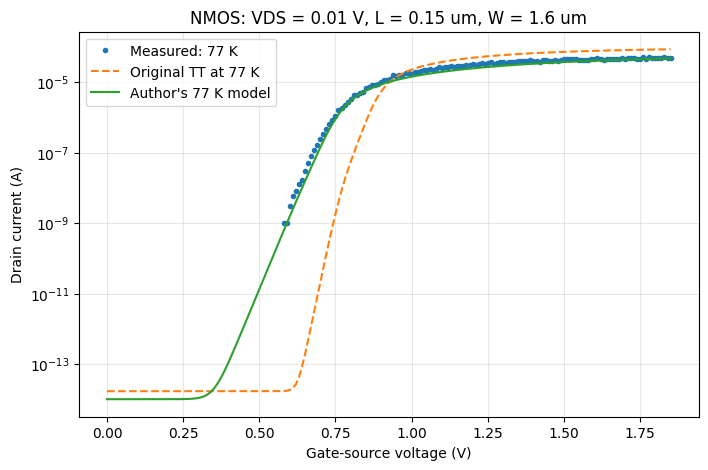

In [75]:
original_sim = np.loadtxt(original_result_path, skiprows=1)
author_sim = np.loadtxt(repo / "idvg_bsim4_77k.txt", skiprows=1)
measured_001 = pd.read_csv(repo / "cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd0p01.csv", skipinitialspace=True)
plt.figure(figsize=(8, 5))
pos = measured_001["Id"] > 0
plt.semilogy(measured_001.loc[pos, "Vg_src"], measured_001.loc[pos, "Id"], ".", label="Measured: 77 K")
pos_original = original_sim[:, -1] > 0
plt.semilogy(original_sim[pos_original, 1], original_sim[pos_original, -1], "--", label="Original TT at 77 K")
pos_author = author_sim[:, -1] > 0
plt.semilogy(author_sim[pos_author, 1], author_sim[pos_author, -1], "-", label="Author's 77 K model")
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Drain current (A)")
plt.title("NMOS: VDS = 0.01 V, L = 0.15 um, W = 1.6 um")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.savefig(repo / "original_vs_author_77K_idvg.png", dpi=300, bbox_inches="tight")
plt.show()

In [76]:
baseline_rows = []
for name, s in [("Original_TT", original_sim), ("Author_77K", author_sim)]:
    prediction = np.interp(measured_001["Vg_src"], s[:, 1], s[:, -1])
    on_mask = measured_001["Id"] >= 1e-6
    sub_mask = measured_001["Id"].between(1e-8, 1e-6)
    on_error = prediction[on_mask] - measured_001.loc[on_mask, "Id"]
    log_error = np.log10(prediction[sub_mask] / measured_001.loc[sub_mask, "Id"])
    baseline_rows.append([name, np.sqrt(np.mean(on_error**2)) * 1e6, (100 * abs(on_error) / measured_001.loc[on_mask, "Id"]).mean(), np.sqrt(np.mean(log_error**2))])
baseline_summary = pd.DataFrame(baseline_rows, columns=["model", "On_RMSE_uA", "On_MAPE_pct", "Sub_log_RMSE_dec"])
display(baseline_summary)
baseline_summary.to_csv(repo / "original_vs_author_77K_errors.csv", index=False)

,model,On_RMSE_uA,On_MAPE_pct,Sub_log_RMSE_dec
0,Original_TT,23.500730,62.333064,4.452531
1,Author_77K,5.130038,15.405066,0.256031


In [77]:
model_sections = re.split(r"(?im)^\s*\.model\s+", original_pm3.read_text())[1:]
for section in model_sections:
    print("\nMODEL:", section.splitlines()[0])
    print("\n".join(line for line in section.splitlines() if re.search(r"\b(lmin|lmax|wmin|wmax|vth0|nfactor|voff|u0)\s*=", line, re.I)))


MODEL: sky130_fd_pr__nfet_01v8_lvt__model.0 nmos
+ lmin = 8e-06 lmax = 1.0e-04 wmin = 7e-06 wmax = 1.0e-4
+ vth0 = {0.417908+sky130_fd_pr__nfet_01v8_lvt__vth0_slope_spectre*(sky130_fd_pr__nfet_01v8_lvt__vth0_slope/sqrt(l*w*mult))}
+ u0 = 0.03198837
+ voff = {-0.11559919+sky130_fd_pr__nfet_01v8_lvt__voff_slope_spectre*(sky130_fd_pr__nfet_01v8_lvt__voff_slope/sqrt(l*w*mult))}
+ nfactor = {1.1019079+sky130_fd_pr__nfet_01v8_lvt__nfactor_slope_spectre*(sky130_fd_pr__nfet_01v8_lvt__nfactor_slope/sqrt(l*w*mult))}

MODEL: sky130_fd_pr__nfet_01v8_lvt__model.1 nmos
+ lmin = 4e-06 lmax = 8e-06 wmin = 7e-06 wmax = 1.0e-4
+ vth0 = {4.065634200e-01+sky130_fd_pr__nfet_01v8_lvt__vth0_slope_spectre*(sky130_fd_pr__nfet_01v8_lvt__vth0_slope2/sqrt(l*w*mult))} lvth0 = 9.048380250e-08 wvth0 = 7.882214154e-08 pvth0 = -6.286814598e-13
+ u0 = 3.155047379e-02 lu0 = 3.492638310e-09 wu0 = 3.042502896e-09 pu0 = -2.426685098e-14
+ voff = {-1.120694636e-01+sky130_fd_pr__nfet_01v8_lvt__voff_slope_spectre*(sky130_fd_

In [78]:
inspect_netlist = original_netlist.replace("dc VG 0 1.85 0.01", "op\nshow m")
inspect_path = pdk_repo / "inspect_original_model.cir"
inspect_path.write_text(inspect_netlist)
inspect_run = subprocess.run(["ngspice", "-b", inspect_path.name], cwd=str(pdk_repo), capture_output=True, text=True)
print(inspect_run.stdout)
print(inspect_run.stderr)


Note: No compatibility mode selected!


Circuit: original sky130 tt extrapolated to 77 k

Doing analysis at TEMP = -196.150000 and TNOM = 27.000000


No. of Data Rows : 1
 BSIM4v5: Berkeley Short Channel IGFET Model-4
     device m.x1.msky130_fd_pr__n
      model x1:sky130_fd_pr__nfet
          l               1.5e-07
          w               1.6e-06
          m                     1
         nf                     1
         sa                     0
         sb                     0
         sd                     0
        sca                     0
        scb                     0
        scc                     0
         sc                     0
        min                     0
         ad                     0
         as                     0
         pd                     0
         ps                     0
        nrd                     0
        nrs                     0
        off                     0
       rbdb                    50
       rbsb                    50

In [79]:
restore_run = subprocess.run(["ngspice", "-b", original_path.name], cwd=str(pdk_repo), capture_output=True, text=True)
assert restore_run.returncode == 0, restore_run.stdout + restore_run.stderr
original_sim = np.loadtxt(original_result_path, skiprows=1)
print("恢复后的扫描点数：", len(original_sim))
inspect_control = "\n".join([".control", "set width=240", "op", "show m : model", "quit", ".endc"])
inspect_text = re.sub(r"(?is)\.control\b.*?\.endc", lambda match: inspect_control, original_netlist)
inspect_path.write_text(inspect_text)
inspect_run = subprocess.run(["ngspice", "-b", inspect_path.name], cwd=str(pdk_repo), capture_output=True, text=True)
print(inspect_run.stdout)
print(inspect_run.stderr)

恢复后的扫描点数： 186

Note: No compatibility mode selected!


Circuit: original sky130 tt extrapolated to 77 k

Doing analysis at TEMP = -196.150000 and TNOM = 27.000000


No. of Data Rows : 1
 BSIM4v5: Berkeley Short Channel IGFET Model-4
     device m.x1.msky130_fd_pr__n
      model x1:sky130_fd_pr__nfet
      model             ?????????

ngspice-42 done

Using SPARSE 1.3 as Direct Linear Solver



In [80]:
inspect_control = "\n".join([".control", "op", "showmod m : lmin lmax wmin wmax", "quit", ".endc"])
inspect_text = re.sub(r"(?is)\.control\b.*?\.endc", lambda match: inspect_control, original_netlist)
inspect_path.write_text(inspect_text)
inspect_run = subprocess.run(["ngspice", "-b", inspect_path.name], cwd=str(pdk_repo), capture_output=True, text=True)
print(inspect_run.stdout)
print(inspect_run.stderr)


Note: No compatibility mode selected!


Circuit: original sky130 tt extrapolated to 77 k

Doing analysis at TEMP = -196.150000 and TNOM = 27.000000


No. of Data Rows : 1
 BSIM4v5 models (Berkeley Short Channel IGFET Model-4)
      model x1:sky130_fd_pr__nfet

       lmin               1.5e-07
       lmax               1.8e-07
       wmin                 1e-06
       wmax              1.65e-06

ngspice-42 done

Using SPARSE 1.3 as Direct Linear Solver



In [81]:
source_text = original_pm3.read_text()
bin_pattern = r"(?ims)(^\s*\.model\s+sky130_fd_pr__nfet_01v8_lvt__model\.55\s+nmos\b.*?)(?=^\s*\.model\b|^\s*\.ends\b|\Z)"
bin_match = re.search(bin_pattern, source_text)
assert bin_match is not None, "未找到第55档"
def add_vth_shift(match):
    expression = match.group(1)
    return "vth0 = {" + expression + " + cal_dvth}"
modified_bin, count = re.subn(r"\bvth0\s*=\s*\{([^}]+)\}", add_vth_shift, bin_match.group(1), count=1, flags=re.I)
assert count == 1, "vth0表达式未成功修改"
calibration_text = source_text[:bin_match.start()] + modified_bin + source_text[bin_match.end():]
calibration_pm3 = pdk_repo / "my_nmos_77k.pm3.spice"
calibration_pm3.write_text(".param cal_dvth=0\n" + calibration_text)
print("校准副本：", calibration_pm3)
print("\n".join(line for line in modified_bin.splitlines() if "cal_dvth" in line))

校准副本： /content/sky130_fd_pr_original/my_nmos_77k.pm3.spice
+ vth0 = {3.199425423e-01+sky130_fd_pr__nfet_01v8_lvt__vth0_slope_spectre*(sky130_fd_pr__nfet_01v8_lvt__vth0_slope1/sqrt(l*w*mult)) + cal_dvth} lvth0 = -1.269893712e-08 wvth0 = -2.019033219e-07 pvth0 = 3.148682306e-14


In [82]:
cal_corner = pdk_repo / "my_nmos_77k.corner.spice"
corner_text = original_corner.read_text().replace('"sky130_fd_pr__nfet_01v8_lvt__tt.pm3.spice"', f'"{calibration_pm3}"')
assert str(calibration_pm3) in corner_text, "模型引用替换失败"
cal_corner.write_text(corner_text)
cal_loader = pdk_repo / "my_nmos_77k_loader.spice"
cal_loader.write_text(minimal_path.read_text().replace(str(original_corner), str(cal_corner)))
cal_netlist = original_netlist.replace(str(minimal_path), str(cal_loader)).replace("original_tt_77k_idvg.txt", "my_nmos_zero_shift.txt")
cal_circuit = pdk_repo / "my_nmos_zero_shift.cir"
cal_circuit.write_text(cal_netlist)
cal_output = pdk_repo / "my_nmos_zero_shift.txt"
cal_output.unlink(missing_ok=True)
cal_run = subprocess.run(["ngspice", "-b", cal_circuit.name], cwd=str(pdk_repo), capture_output=True, text=True)
assert cal_run.returncode == 0, cal_run.stdout + cal_run.stderr
zero_sim = np.loadtxt(cal_output, skiprows=1)
assert zero_sim.shape == original_sim.shape, "输出尺寸不一致"
print("扫描点数：", len(zero_sim))
print("最大电流差：", np.max(np.abs(zero_sim[:, -1] - original_sim[:, -1])), "A")
print("与原版一致：", np.allclose(zero_sim, original_sim, rtol=1e-8, atol=1e-18))

扫描点数： 186
最大电流差： 0.0 A
与原版一致： True


In [84]:
scan_rows = []
plt.figure(figsize=(8, 5))
positive_mask = measured_001["Id"] > 0
plt.semilogy(s[valid, 1], s[valid, -1], label=f"delta vth0 = {delta:+.3f} V")
for delta in [-0.20, -0.175, -0.15, -0.125, -0.10]:
    calibration_pm3.write_text(f".param cal_dvth={delta}\n" + calibration_text)
    cal_output.unlink(missing_ok=True)
    run = subprocess.run(["ngspice", "-b", cal_circuit.name], cwd=str(pdk_repo), capture_output=True, text=True)
    assert run.returncode == 0, run.stdout + run.stderr
    s = np.loadtxt(cal_output, skiprows=1)
    prediction = np.interp(measured_001["Vg_src"], s[:, 1], s[:, -1])
    mask = measured_001["Id"].between(1e-8, 1e-6)
    log_rmse = np.sqrt(np.mean(np.log10(prediction[mask] / measured_001.loc[mask, "Id"])**2))
    scan_rows.append([delta, log_rmse])
    valid = s[:, -1] > 0
    plt.semilogy(s[valid, 1], s[valid, -1], label=f"delta vth0 = {delta:+.2f} V")
calibration_pm3.write_text(".param cal_dvth=0\n" + calibration_text)
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Drain current (A)")
plt.title("vth0 sensitivity: 77 K, VDS = 0.01 V")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()
display(pd.DataFrame(scan_rows, columns=["delta_vth0_V", "Sub_log_RMSE_dec"]))

NameError: name 'valid' is not defined

<Figure size 800x500 with 0 Axes>

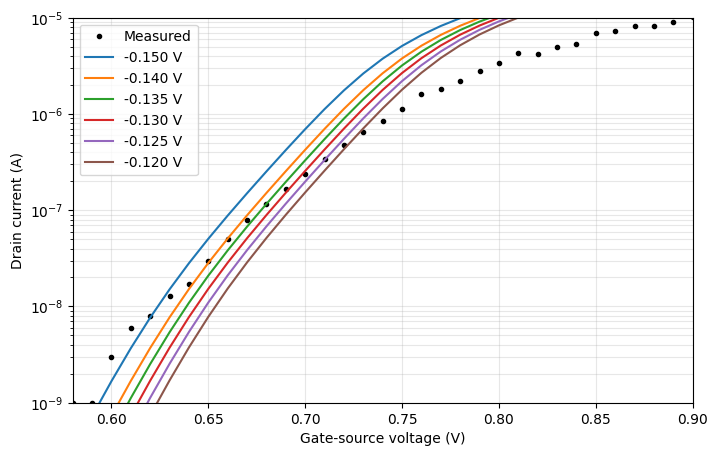

,delta_vth0_V,Sub_log_RMSE_dec
0,-0.150,0.419601
1,-0.140,0.264456
2,-0.135,0.233183
3,-0.130,0.259320
4,-0.125,0.333638
5,-0.120,0.435269


本轮最佳偏移： -0.135 V


In [86]:
fine_rows = []
plt.close("all")
plt.figure(figsize=(8, 5))
meas_mask = measured_001["Id"] > 0
plt.semilogy(measured_001.loc[meas_mask, "Vg_src"], measured_001.loc[meas_mask, "Id"], "k.", label="Measured")
for delta in [-0.15, -0.14, -0.135, -0.13, -0.125, -0.12]:
    calibration_pm3.write_text(f".param cal_dvth={delta}\n" + calibration_text)
    cal_output.unlink(missing_ok=True)
    run = subprocess.run(["ngspice", "-b", cal_circuit.name], cwd=str(pdk_repo), capture_output=True, text=True)
    assert run.returncode == 0, run.stdout + run.stderr
    s = np.loadtxt(cal_output, skiprows=1)
    prediction = np.interp(measured_001["Vg_src"], s[:, 1], s[:, -1])
    mask = measured_001["Id"].between(1e-8, 1e-6)
    assert np.all(prediction[mask] > 0), "比较区间出现非正仿真电流"
    score = np.sqrt(np.mean(np.log10(prediction[mask] / measured_001.loc[mask, "Id"])**2))
    fine_rows.append([delta, score])
    valid = s[:, -1] > 0
    plt.semilogy(s[valid, 1], s[valid, -1], label=f"{delta:+.3f} V")
calibration_pm3.write_text(".param cal_dvth=0\n" + calibration_text)
plt.xlim(0.58, 0.90)
plt.ylim(1e-9, 1e-5)
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Drain current (A)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()
fine_summary = pd.DataFrame(fine_rows, columns=["delta_vth0_V", "Sub_log_RMSE_dec"])
display(fine_summary)
best_delta = float(fine_summary.loc[fine_summary["Sub_log_RMSE_dec"].idxmin(), "delta_vth0_V"])
print("本轮最佳偏移：", best_delta, "V")

当前 vth0 偏移： -0.135 V
导通区 RMSE： 32.24667976434642 uA
导通区平均绝对相对误差： 113.40542534913936 %


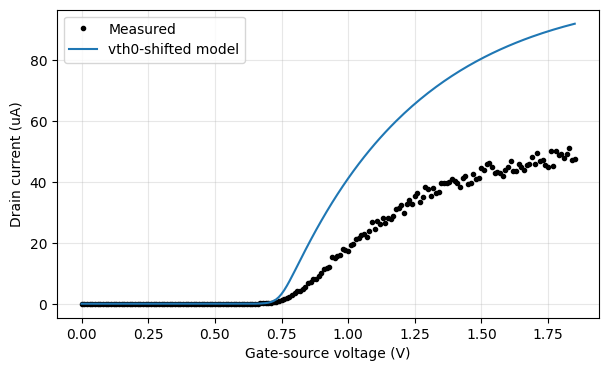

In [87]:
calibration_pm3.write_text(f".param cal_dvth={best_delta}\n" + calibration_text)
cal_output.unlink(missing_ok=True)
run = subprocess.run(["ngspice", "-b", cal_circuit.name], cwd=str(pdk_repo), capture_output=True, text=True)
assert run.returncode == 0, run.stdout + run.stderr
shifted_sim = np.loadtxt(cal_output, skiprows=1)
shifted_prediction = np.interp(measured_001["Vg_src"], shifted_sim[:, 1], shifted_sim[:, -1])
on_mask = measured_001["Id"] >= 1e-6
on_error = shifted_prediction[on_mask] - measured_001.loc[on_mask, "Id"]
print("当前 vth0 偏移：", best_delta, "V")
print("导通区 RMSE：", np.sqrt(np.mean(on_error**2)) * 1e6, "uA")
print("导通区平均绝对相对误差：", (100 * abs(on_error) / measured_001.loc[on_mask, "Id"]).mean(), "%")
plt.figure(figsize=(7, 4))
plt.plot(measured_001["Vg_src"], measured_001["Id"] * 1e6, "k.", label="Measured")
plt.plot(shifted_sim[:, 1], shifted_sim[:, -1] * 1e6, label="vth0-shifted model")
plt.xlabel("Gate-source voltage (V)")
plt.ylabel("Drain current (uA)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [88]:
current_text = calibration_pm3.read_text()

current_bin = re.search(bin_pattern, current_text).group(1)

print("\n".join(line for line in current_bin.splitlines() if re.search(r"\b(?:u0|ua|ub|uc|ute)\s*=", line, re.I)))

+ ua = -9.557611658e-11 lua = -3.379905572e-16 wua = -2.668051655e-15 pua = 4.160826556e-22
+ ub = 1.344944324e-18 lub = 1.742905241e-25 wub = 1.252797190e-24 pub = -1.953737218e-31
+ uc = -6.738595665e-11 luc = 1.532084359e-17 wuc = 1.774818658e-16 puc = -2.767829697e-23
+ u0 = 4.308038042e-02 lu0 = -4.480159737e-09 wu0 = -3.800182135e-08 pu0 = 5.926384040e-15
+ ute = -2.107239553e+00 lute = 5.422998334e-08 wute = -8.904100744e-08 pute = 1.388594511e-14


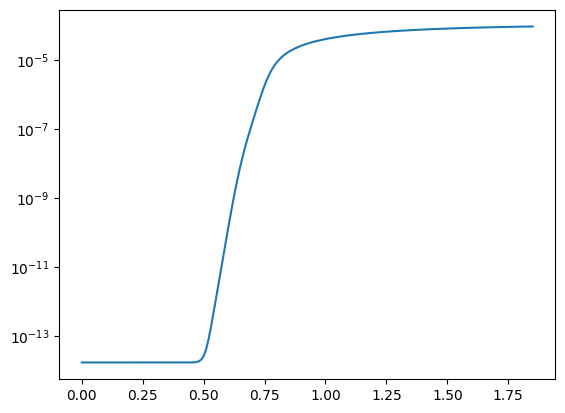

In [89]:
plt.semilogy(s[valid, 1], s[valid, -1], label=f"delta vth0 = {delta:+.3f} V")

In [90]:
current_text = calibration_pm3.read_text()

current_bin = re.search(bin_pattern, current_text).group(1)

print("\n".join(line for line in current_bin.splitlines() if re.search(r"\b(?:u0|ua|ub|uc|ute)\s*=", line, re.I)))

+ ua = -9.557611658e-11 lua = -3.379905572e-16 wua = -2.668051655e-15 pua = 4.160826556e-22
+ ub = 1.344944324e-18 lub = 1.742905241e-25 wub = 1.252797190e-24 pub = -1.953737218e-31
+ uc = -6.738595665e-11 luc = 1.532084359e-17 wuc = 1.774818658e-16 puc = -2.767829697e-23
+ u0 = 4.308038042e-02 lu0 = -4.480159737e-09 wu0 = -3.800182135e-08 pu0 = 5.926384040e-15
+ ute = -2.107239553e+00 lute = 5.422998334e-08 wute = -8.904100744e-08 pute = 1.388594511e-14


In [91]:
mobility_bin = re.search(bin_pattern, calibration_text)

mobility_block, count = re.subn(r"\b(u0|lu0|wu0|pu0)\s*=\s*([+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?)", lambda m: f"{m.group(1)} = ({m.group(2)} * cal_mu)", mobility_bin.group(1), flags=re.I)

assert count == 4, f"应修改 4 个参数，实际修改 {count} 个"

mobility_text = calibration_text[:mobility_bin.start()] + mobility_block + calibration_text[mobility_bin.end():]

calibration_pm3.write_text(".param cal_dvth=-0.135 cal_mu=0.5\n" + mobility_text)

cal_output.unlink(missing_ok=True)

run = subprocess.run(["ngspice", "-b", cal_circuit.name], cwd=str(pdk_repo), capture_output=True, text=True)

assert run.returncode == 0, run.stdout + run.stderr

mu_sim = np.loadtxt(cal_output, skiprows=1)

assert len(mu_sim) == 186, "扫描点数不正确"

mu_prediction = np.interp(measured_001["Vg_src"], mu_sim[:, 1], mu_sim[:, -1])

measured_id = measured_001["Id"].to_numpy()

on = measured_id >= 1e-6

sub = (measured_id >= 1e-8) & (measured_id <= 1e-6)

assert np.all(mu_prediction[sub] > 0), "亚阈值预测电流必须为正"

print("迁移率缩放：0.5；vth0 偏移：-0.135 V")

print("导通区 RMSE：", np.sqrt(np.mean((mu_prediction[on] - measured_id[on])**2)) * 1e6, "uA")

print("导通区 MAPE：", np.mean(np.abs(mu_prediction[on] / measured_id[on] - 1)) * 100, "%")

print("亚阈值对数 RMSE：", np.sqrt(np.mean((np.log10(mu_prediction[sub]) - np.log10(measured_id[sub]))**2)), "dec")

迁移率缩放：0.5；vth0 偏移：-0.135 V
导通区 RMSE： 14.130307611298008 uA
导通区 MAPE： 45.30317243670605 %
亚阈值对数 RMSE： 0.33318294822728217 dec


In [92]:
joint_rows = []

for dv, mu in [(dv, mu)
               for dv in [-0.15, -0.135, -0.12]
               for mu in [0.25, 0.4, 0.55, 0.7]]:
    calibration_pm3.write_text(
        f".param cal_dvth={dv} cal_mu={mu}\n" + mobility_text
    )
    cal_output.unlink(missing_ok=True)
    run = subprocess.run(
        ["ngspice", "-b", cal_circuit.name],
        cwd=str(pdk_repo), capture_output=True, text=True
    )
    assert run.returncode == 0, run.stdout + run.stderr
    scan = np.loadtxt(cal_output, skiprows=1)
    assert len(scan) == 186
    pred = np.interp(measured_001["Vg_src"], scan[:, 1], scan[:, -1])
    assert np.all(pred[sub] > 0)

    rmse = np.sqrt(np.mean((pred[on] - measured_id[on])**2)) * 1e6
    mape = np.mean(np.abs(pred[on] / measured_id[on] - 1)) * 100
    log_rmse = np.sqrt(np.mean(
        (np.log10(pred[sub]) - np.log10(measured_id[sub]))**2
    ))
    joint_rows.append([dv, mu, rmse, mape, log_rmse])

joint_summary = pd.DataFrame(
    joint_rows,
    columns=["delta_vth0_V", "mu_scale",
             "On_RMSE_uA", "On_MAPE_pct", "Sub_log_RMSE_dec"]
)

# 扫描后恢复到刚才测试过的设置
calibration_pm3.write_text(
    ".param cal_dvth=-0.135 cal_mu=0.5\n" + mobility_text
)

display(joint_summary.sort_values("On_RMSE_uA").reset_index(drop=True))

,delta_vth0_V,mu_scale,On_RMSE_uA,On_MAPE_pct,Sub_log_RMSE_dec
0,-0.150,0.25,3.224473,10.373214,0.264958
1,-0.135,0.25,3.764164,10.576207,0.580873
2,-0.120,0.25,4.364204,15.105973,0.948953
3,-0.120,0.40,7.774464,19.840815,0.760695
4,-0.135,0.40,8.485713,25.728151,0.405775
5,-0.150,0.40,9.226642,33.138785,0.183685
6,-0.120,0.55,15.764449,45.492514,0.638940
7,-0.135,0.55,16.615703,54.097589,0.305839
8,-0.150,0.55,17.477407,63.305060,0.230260
9,-0.120,0.70,22.051411,67.144418,0.551739


In [93]:
joint_rows = []

for dv, mu in [(dv, mu)
                              for dv in [-0.18, -0.165, -0.15]
               for mu in [0.15, 0.20, 0.25, 0.30]]:
    calibration_pm3.write_text(
        f".param cal_dvth={dv} cal_mu={mu}\n" + mobility_text
    )
    cal_output.unlink(missing_ok=True)
    run = subprocess.run(
        ["ngspice", "-b", cal_circuit.name],
        cwd=str(pdk_repo), capture_output=True, text=True
    )
    assert run.returncode == 0, run.stdout + run.stderr
    scan = np.loadtxt(cal_output, skiprows=1)
    assert len(scan) == 186
    pred = np.interp(measured_001["Vg_src"], scan[:, 1], scan[:, -1])
    assert np.all(pred[sub] > 0)

    rmse = np.sqrt(np.mean((pred[on] - measured_id[on])**2)) * 1e6
    mape = np.mean(np.abs(pred[on] / measured_id[on] - 1)) * 100
    log_rmse = np.sqrt(np.mean(
        (np.log10(pred[sub]) - np.log10(measured_id[sub]))**2
    ))
    joint_rows.append([dv, mu, rmse, mape, log_rmse])

joint_summary = pd.DataFrame(
    joint_rows,
    columns=["delta_vth0_V", "mu_scale",
             "On_RMSE_uA", "On_MAPE_pct", "Sub_log_RMSE_dec"]
)

# 扫描后恢复到刚才测试过的设置
calibration_pm3.write_text(
    ".param cal_dvth=-0.135 cal_mu=0.5\n" + mobility_text
)

display(joint_summary.sort_values("On_RMSE_uA").reset_index(drop=True))

,delta_vth0_V,mu_scale,On_RMSE_uA,On_MAPE_pct,Sub_log_RMSE_dec
0,-0.180,0.25,2.462153,14.688184,0.414284
1,-0.165,0.25,2.776065,12.317754,0.181601
2,-0.150,0.30,2.837418,10.562741,0.215958
3,-0.150,0.25,3.224473,10.373214,0.264958
4,-0.165,0.30,3.315934,15.722004,0.240197
5,-0.180,0.30,3.890527,21.470253,0.489616
6,-0.180,0.20,6.411941,21.179439,0.322200
7,-0.165,0.20,6.928822,20.514095,0.137141
8,-0.150,0.20,7.467606,20.605229,0.339988
9,-0.180,0.15,11.840886,33.034359,0.205712


VDS = 0.37 V；Δvth0 = -0.165 V；mu_scale = 0.25
导通区点数： 115
导通区 RMSE： 83.82130133662866 uA
导通区 MAPE： 43.66029249640679 %
亚阈值点数： 11
亚阈值对数 RMSE： 0.5349990889062448 dec


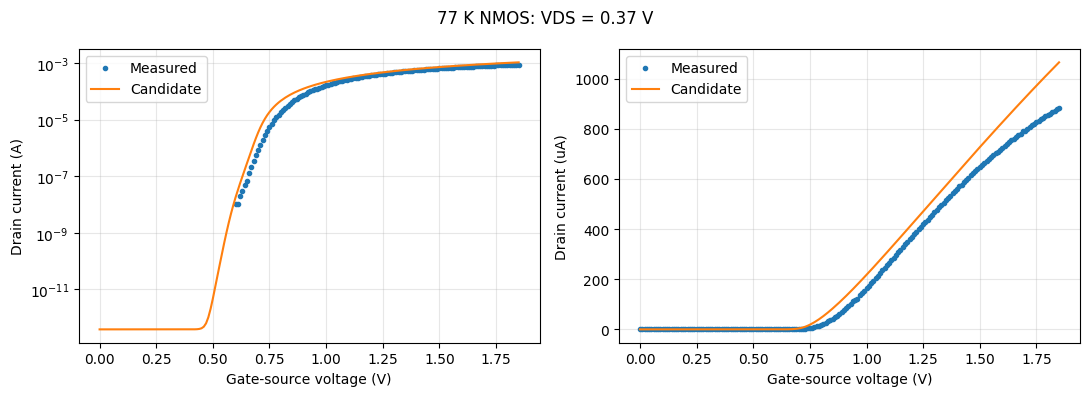

In [94]:
candidate_dvth = -0.165
candidate_mu = 0.25

calibration_pm3.write_text(
    f".param cal_dvth={candidate_dvth} cal_mu={candidate_mu}\n"
    + mobility_text
)

text_037, count = re.subn(
    r"(?im)^\s*VD\s+d\s+0\s+[^\s]+[^\n]*$",
    "VD d 0 0.37",
    cal_netlist
)
assert count == 1, "没有准确找到漏极电压源，请检查网表"

text_037 = text_037.replace(
    "my_nmos_zero_shift.txt", "my_nmos_candidate_037.txt"
)
assert "wrdata my_nmos_candidate_037.txt" in text_037

circuit_037 = pdk_repo / "my_nmos_candidate_037.cir"
output_037 = pdk_repo / "my_nmos_candidate_037.txt"
circuit_037.write_text(text_037)
output_037.unlink(missing_ok=True)

run = subprocess.run(
    ["ngspice", "-b", circuit_037.name],
    cwd=str(pdk_repo), capture_output=True, text=True
)
assert run.returncode == 0, run.stdout + run.stderr

candidate_037 = np.loadtxt(output_037, skiprows=1)
assert len(candidate_037) == 186

data_037 = pd.read_csv(
    repo / "cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd0p37.csv",
    skipinitialspace=True
)
vg = data_037["Vg_src"].to_numpy()
measured = data_037["Id"].to_numpy()
predicted = np.interp(
    vg, candidate_037[:, 1], candidate_037[:, -1]
)

on_037 = measured >= 1e-6
sub_037 = (measured >= 1e-8) & (measured <= 1e-6)
assert np.all(predicted[sub_037] > 0)

print("VDS = 0.37 V；Δvth0 = -0.165 V；mu_scale = 0.25")
print("导通区点数：", on_037.sum())
print("导通区 RMSE：",
      np.sqrt(np.mean(
          (predicted[on_037] - measured[on_037])**2
      )) * 1e6, "uA")
print("导通区 MAPE：",
      np.mean(np.abs(
          predicted[on_037] / measured[on_037] - 1
      )) * 100, "%")
print("亚阈值点数：", sub_037.sum())
print("亚阈值对数 RMSE：",
      np.sqrt(np.mean(
          (np.log10(predicted[sub_037])
           - np.log10(measured[sub_037]))**2
      )), "dec")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
positive = measured > 0

axes[0].semilogy(vg[positive], measured[positive], ".", label="Measured")
axes[0].semilogy(candidate_037[:, 1], candidate_037[:, -1],
                 label="Candidate")
axes[0].set_ylabel("Drain current (A)")

axes[1].plot(vg, measured * 1e6, ".", label="Measured")
axes[1].plot(candidate_037[:, 1], candidate_037[:, -1] * 1e6,
             label="Candidate")
axes[1].set_ylabel("Drain current (uA)")

for ax in axes:
    ax.set_xlabel("Gate-source voltage (V)")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("77 K NMOS: VDS = 0.37 V")
plt.tight_layout()
plt.show()

In [95]:
comparison_rows = []

for dv, mu in [(-0.165, 0.25), (-0.150, 0.30), (-0.135, 0.25)]:
    calibration_pm3.write_text(
        f".param cal_dvth={dv} cal_mu={mu}\n" + mobility_text
    )

    for vds, circuit, output, data in [
        (0.01, cal_circuit, cal_output, measured_001),
        (0.37, circuit_037, output_037, data_037)
    ]:
        output.unlink(missing_ok=True)
        run = subprocess.run(
            ["ngspice", "-b", circuit.name],
            cwd=str(pdk_repo), capture_output=True, text=True
        )
        assert run.returncode == 0, run.stdout + run.stderr
        scan = np.loadtxt(output, skiprows=1)
        assert len(scan) == 186

        measured = data["Id"].to_numpy()
        predicted = np.interp(
            data["Vg_src"], scan[:, 1], scan[:, -1]
        )
        on_mask = measured >= 1e-6
        sub_mask = (measured >= 1e-8) & (measured <= 1e-6)
        assert np.all(predicted[sub_mask] > 0)

        rmse = np.sqrt(np.mean(
            (predicted[on_mask] - measured[on_mask])**2
        )) * 1e6
        mape = np.mean(np.abs(
            predicted[on_mask] / measured[on_mask] - 1
        )) * 100
        log_rmse = np.sqrt(np.mean(
            (np.log10(predicted[sub_mask])
             - np.log10(measured[sub_mask]))**2
        ))

        comparison_rows.append([dv, mu, vds, rmse, mape, log_rmse])

two_bias_summary = pd.DataFrame(
    comparison_rows,
    columns=["delta_vth0_V", "mu_scale", "VDS_V",
             "On_RMSE_uA", "On_MAPE_pct", "Sub_log_RMSE_dec"]
)
display(two_bias_summary)

,delta_vth0_V,mu_scale,VDS_V,On_RMSE_uA,On_MAPE_pct,Sub_log_RMSE_dec
0,-0.165,0.25,0.01,2.776065,12.317754,0.181601
1,-0.165,0.25,0.37,83.821301,43.660292,0.534999
2,-0.150,0.30,0.01,2.837418,10.562741,0.215958
3,-0.150,0.30,0.37,95.875475,38.804044,0.286443
4,-0.135,0.25,0.01,3.764164,10.576207,0.580873
5,-0.135,0.25,0.37,58.384456,15.768034,0.260071


In [96]:
inspect_bin = re.search(bin_pattern, calibration_text).group(1)
names = r"\b(?:nfactor|voff|eta0|etab|dsub|dvt0|dvt1|dvt2)\s*="
print("\n".join(line for line in inspect_bin.splitlines() if re.search(names, line, re.I)))

+ dvt0 = 0.07665
+ dvt1 = 0.1252
+ dvt2 = -0.05637
+ voff = {-2.986804670e-01+sky130_fd_pr__nfet_01v8_lvt__voff_slope_spectre*(sky130_fd_pr__nfet_01v8_lvt__voff_slope/sqrt(l*w*mult))} lvoff = 3.285808158e-08 wvoff = 2.989792333e-07 pvoff = -4.662581144e-14
+ nfactor = {3.513481879e-01+sky130_fd_pr__nfet_01v8_lvt__nfactor_slope_spectre*(sky130_fd_pr__nfet_01v8_lvt__nfactor_slope/sqrt(l*w*mult))} lnfactor = 4.461539260e-07 wnfactor = 2.159823686e-06 pnfactor = -3.368245039e-13
+ eta0 = -1.362264692e-01 leta0 = 3.284221713e-08 weta0 = 3.045205096e-07 peta0 = -4.748997348e-14
+ etab = -1.754397557e-01 letab = 2.424309539e-08 wetab = 1.143346712e-07 petab = -1.783049197e-14
+ dsub = 6.701504754e-01 ldsub = -5.165845237e-8


In [97]:
# 从已有的迁移率校准文本建立副本，避免重复叠加修改
shape_match = re.search(bin_pattern, mobility_text)
shape_block, count = re.subn(
    r"\bnfactor\s*=\s*\{([^}]+)\}",
    lambda m: "nfactor = {" + m.group(1) + " + cal_dn}",
    shape_match.group(1), count=1, flags=re.I
)
assert count == 1

shape_text = (
    mobility_text[:shape_match.start()]
    + shape_block
    + mobility_text[shape_match.end():]
)

shape_rows = []

for dn in [-0.3, 0.0, 0.3]:
    calibration_pm3.write_text(
        f".param cal_dvth=-0.150 cal_mu=0.25 cal_dn={dn}\n"
        + shape_text
    )

    for vds, circuit, output, data in [
        (0.01, cal_circuit, cal_output, measured_001),
        (0.37, circuit_037, output_037, data_037)
    ]:
        output.unlink(missing_ok=True)
        run = subprocess.run(
            ["ngspice", "-b", circuit.name],
            cwd=str(pdk_repo), capture_output=True, text=True
        )
        assert run.returncode == 0, run.stdout + run.stderr
        scan = np.loadtxt(output, skiprows=1)
        assert len(scan) == 186

        measured = data["Id"].to_numpy()
        predicted = np.interp(
            data["Vg_src"], scan[:, 1], scan[:, -1]
        )
        on = measured >= 1e-6
        sub = (measured >= 1e-8) & (measured <= 1e-6)
        assert np.all(predicted[sub] > 0)

        rmse = np.sqrt(np.mean(
            (predicted[on] - measured[on])**2
        )) * 1e6
        mape = np.mean(np.abs(
            predicted[on] / measured[on] - 1
        )) * 100
        log_rmse = np.sqrt(np.mean(
            (np.log10(predicted[sub])
             - np.log10(measured[sub]))**2
        ))

        shape_rows.append([dn, vds, rmse, mape, log_rmse])

# 恢复本次测试的零增量设置
calibration_pm3.write_text(
    ".param cal_dvth=-0.150 cal_mu=0.25 cal_dn=0\n" + shape_text
)

shape_summary = pd.DataFrame(
    shape_rows,
    columns=["delta_nfactor", "VDS_V",
             "On_RMSE_uA", "On_MAPE_pct", "Sub_log_RMSE_dec"]
)
display(shape_summary)

,delta_nfactor,VDS_V,On_RMSE_uA,On_MAPE_pct,Sub_log_RMSE_dec
0,-0.3,0.01,3.224374,10.339837,0.299805
1,-0.3,0.37,70.757328,28.247931,0.195284
2,0.0,0.01,3.224473,10.373214,0.264958
3,0.0,0.37,70.757850,28.407085,0.218645
4,0.3,0.01,3.224579,10.407398,0.233590
5,0.3,0.37,70.758415,28.568567,0.244732


In [98]:
eta_match = re.search(bin_pattern, shape_text)
eta_block, count = re.subn(
    r"\beta0\s*=\s*([+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?)",
    lambda m: "eta0 = (" + m.group(1) + " + cal_deta)",
    eta_match.group(1), count=1, flags=re.I
)
assert count == 1

eta_text = (
    shape_text[:eta_match.start()]
    + eta_block
    + shape_text[eta_match.end():]
)
print("eta0 测试副本已建立")

eta0 测试副本已建立


In [99]:
import re
import subprocess
import numpy as np
import pandas as pd

# 1. 从迁移率校准文本重新建立 nfactor 测试副本
shape_match = re.search(bin_pattern, mobility_text)
assert shape_match is not None, "没有找到目标模型 bin"

shape_block, count = re.subn(
    r"\bnfactor\s*=\s*\{([^}]+)\}",
    lambda m: "nfactor = {" + m.group(1) + " + cal_dn}",
    shape_match.group(1),
    count=1,
    flags=re.I
)
assert count == 1, "nfactor 修改失败"

shape_text = (
    mobility_text[:shape_match.start()]
    + shape_block
    + mobility_text[shape_match.end():]
)

# 2. 加入 eta0 调节量
eta_match = re.search(bin_pattern, shape_text)
assert eta_match is not None, "没有找到目标模型 bin"

eta_block, count = re.subn(
    r"\beta0\s*=\s*([+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?)",
    lambda m: "eta0 = (" + m.group(1) + " + cal_deta)",
    eta_match.group(1),
    count=1,
    flags=re.I
)
assert count == 1, "eta0 修改失败"

eta_text = (
    shape_text[:eta_match.start()]
    + eta_block
    + shape_text[eta_match.end():]
)

# 3. 固定其他参数，扫描 eta0 增量
eta_rows = []

try:
    for deta in [-0.02, 0.0, 0.02]:
        calibration_pm3.write_text(
            f".param cal_dvth=-0.150 cal_mu=0.25 "
            f"cal_dn=0 cal_deta={deta}\n"
            + eta_text
        )

        for vds, circuit, output, data in [
            (0.01, cal_circuit, cal_output, measured_001),
            (0.37, circuit_037, output_037, data_037)
        ]:
            output.unlink(missing_ok=True)

            run = subprocess.run(
                ["ngspice", "-b", circuit.name],
                cwd=str(pdk_repo),
                capture_output=True,
                text=True
            )
            assert run.returncode == 0, run.stdout + run.stderr
            assert output.exists(), f"没有生成结果文件：{output}"

            scan = np.loadtxt(output, skiprows=1)
            assert scan.ndim == 2 and len(scan) == 186, "扫描点数不正确"
            assert np.all(np.isfinite(scan)), "仿真结果包含无效数值"
            assert np.all(np.diff(scan[:, 1]) > 0), "扫描电压没有递增"

            measured = data["Id"].to_numpy()
            vg = data["Vg_src"].to_numpy()
            assert vg.min() >= scan[:, 1].min()
            assert vg.max() <= scan[:, 1].max()

            predicted = np.interp(vg, scan[:, 1], scan[:, -1])

            on = measured >= 1e-6
            sub = (measured >= 1e-8) & (measured <= 1e-6)
            assert on.any() and sub.any(), "误差统计区间没有数据"
            assert np.all(predicted[sub] > 0), "亚阈值预测电流必须为正"

            rmse = np.sqrt(np.mean(
                (predicted[on] - measured[on])**2
            )) * 1e6

            mape = np.mean(np.abs(
                predicted[on] / measured[on] - 1
            )) * 100

            log_rmse = np.sqrt(np.mean(
                (np.log10(predicted[sub])
                 - np.log10(measured[sub]))**2
            ))

            eta_rows.append([
                deta, vds, rmse, mape, log_rmse
            ])

finally:
    # 无论扫描是否成功，都恢复到 eta0 零增量设置
    calibration_pm3.write_text(
        ".param cal_dvth=-0.150 cal_mu=0.25 cal_dn=0 cal_deta=0\n"
        + eta_text
    )

# 4. 显示六行比较结果
eta_summary = pd.DataFrame(
    eta_rows,
    columns=[
        "delta_eta0",
        "VDS_V",
        "On_RMSE_uA",
        "On_MAPE_pct",
        "Sub_log_RMSE_dec"
    ]
)

display(eta_summary)
print("模型文件已恢复：Δvth0=-0.150 V，mu_scale=0.25，Δnfactor=0，Δeta0=0")

,delta_eta0,VDS_V,On_RMSE_uA,On_MAPE_pct,Sub_log_RMSE_dec
0,-0.02,0.01,3.230061,10.353855,0.267964
1,-0.02,0.37,65.545348,22.883330,0.147699
2,0.00,0.01,3.224473,10.373214,0.264958
3,0.00,0.37,70.757850,28.407085,0.218645
4,0.02,0.01,3.218897,10.392601,0.261973
5,0.02,0.37,76.085407,34.379853,0.343023


模型文件已恢复：Δvth0=-0.150 V，mu_scale=0.25，Δnfactor=0，Δeta0=0


In [100]:
eta_rows = []

try:
    for deta in [-0.08, -0.06, -0.04, -0.02, 0.0]:
        calibration_pm3.write_text(
            f".param cal_dvth=-0.150 cal_mu=0.25 "
            f"cal_dn=0 cal_deta={deta}\n"
            + eta_text
        )

        for vds, circuit, output, data in [
            (0.01, cal_circuit, cal_output, measured_001),
            (0.37, circuit_037, output_037, data_037)
        ]:
            output.unlink(missing_ok=True)

            run = subprocess.run(
                ["ngspice", "-b", circuit.name],
                cwd=str(pdk_repo),
                capture_output=True,
                text=True
            )
            assert run.returncode == 0, run.stdout + run.stderr
            assert output.exists(), f"没有生成结果文件：{output}"

            scan = np.loadtxt(output, skiprows=1)
            assert scan.ndim == 2 and len(scan) == 186
            assert np.all(np.isfinite(scan))
            assert np.all(np.diff(scan[:, 1]) > 0)

            measured = data["Id"].to_numpy()
            vg = data["Vg_src"].to_numpy()
            assert vg.min() >= scan[:, 1].min()
            assert vg.max() <= scan[:, 1].max()

            predicted = np.interp(vg, scan[:, 1], scan[:, -1])
            on = measured >= 1e-6
            sub = (measured >= 1e-8) & (measured <= 1e-6)
            assert on.any() and sub.any()
            assert np.all(predicted[sub] > 0)

            rmse = np.sqrt(np.mean(
                (predicted[on] - measured[on])**2
            )) * 1e6

            mape = np.mean(np.abs(
                predicted[on] / measured[on] - 1
            )) * 100

            log_rmse = np.sqrt(np.mean(
                (np.log10(predicted[sub])
                 - np.log10(measured[sub]))**2
            ))

            eta_rows.append([deta, vds, rmse, mape, log_rmse])

finally:
    calibration_pm3.write_text(
        ".param cal_dvth=-0.150 cal_mu=0.25 cal_dn=0 cal_deta=0\n"
        + eta_text
    )

eta_extended_summary = pd.DataFrame(
    eta_rows,
    columns=[
        "delta_eta0", "VDS_V",
        "On_RMSE_uA", "On_MAPE_pct", "Sub_log_RMSE_dec"
    ]
)

display(eta_extended_summary)
print("模型文件已恢复到 Δeta0=0；扫描结果文件仅对应最后一次运行。")

,delta_eta0,VDS_V,On_RMSE_uA,On_MAPE_pct,Sub_log_RMSE_dec
0,-0.08,0.01,3.246221,10.298227,0.276729
1,-0.08,0.37,51.452285,10.664562,0.476701
2,-0.06,0.01,3.241269,10.315215,0.274032
3,-0.06,0.37,55.580643,13.328183,0.341208
4,-0.04,0.01,3.235659,10.334521,0.270988
5,-0.04,0.37,60.474533,17.792661,0.208143
6,-0.02,0.01,3.230061,10.353855,0.267964
7,-0.02,0.37,65.545348,22.883330,0.147699
8,0.00,0.01,3.224473,10.373214,0.264958
9,0.00,0.37,70.757850,28.407085,0.218645


模型文件已恢复到 Δeta0=0；扫描结果文件仅对应最后一次运行。


比较点数： 181
输出曲线 RMSE： 38.56427591420188 uA
输出曲线 MAPE： 12.156963653200652 %


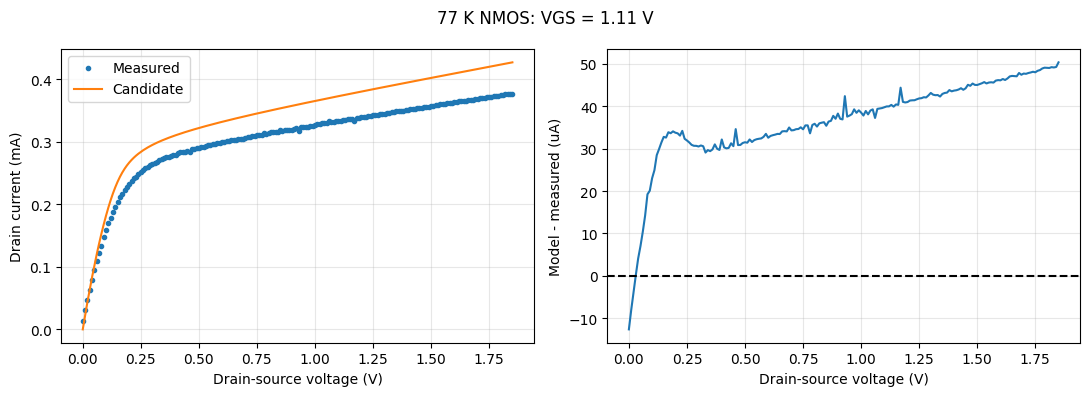

In [101]:
import matplotlib.pyplot as plt

# 暂定候选参数，不代表最终校准完成
calibration_pm3.write_text(
    ".param cal_dvth=-0.150 cal_mu=0.25 cal_dn=0 cal_deta=-0.02\n"
    + eta_text
)

# 从已有转移曲线网表生成输出曲线网表
output_text, count = re.subn(
    r"(?im)^\s*VG\s+g\s+0\s+[^\n]+$",
    "VG g 0 1.11",
    cal_netlist
)
assert count == 1, "没有准确找到栅极电压源"

output_text, count = re.subn(
    r"(?im)^\s*dc\s+VG\s+[^\n]+$",
    "dc VD 0 1.85 0.01",
    output_text
)
assert count == 1, "没有准确找到 DC 扫描命令"

output_text, count = re.subn(
    r"(?im)^\s*wrdata\s+[^\n]+$",
    "wrdata my_candidate_idvd_111.txt v(d) idrain",
    output_text
)
assert count == 1, "没有准确找到结果导出命令"

output_circuit = pdk_repo / "my_candidate_idvd_111.cir"
output_file = pdk_repo / "my_candidate_idvd_111.txt"
output_circuit.write_text(output_text)
output_file.unlink(missing_ok=True)

run = subprocess.run(
    ["ngspice", "-b", output_circuit.name],
    cwd=str(pdk_repo), capture_output=True, text=True
)
assert run.returncode == 0, run.stdout + run.stderr
assert output_file.exists()

output_scan = np.loadtxt(output_file, skiprows=1)
assert output_scan.ndim == 2 and len(output_scan) == 186
assert np.all(np.isfinite(output_scan))
assert np.all(np.diff(output_scan[:, 1]) > 0)

output_data = pd.read_csv(
    repo / "cryo_data/nmos_FET_len_0p15_wid_1p6/idvd_Vg1p11.csv",
    skipinitialspace=True
)
assert np.allclose(output_data["Vg_src"], 1.11)

vd = output_data["Vd_src"].to_numpy()
measured = output_data["Id"].to_numpy()
assert vd.min() >= output_scan[:, 1].min()
assert vd.max() <= output_scan[:, 1].max()

predicted = np.interp(vd, output_scan[:, 1], output_scan[:, -1])
compare = (vd >= 0.05) & (measured > 0)
error_uA = (predicted - measured) * 1e6

print("比较点数：", compare.sum())
print("输出曲线 RMSE：",
      np.sqrt(np.mean(error_uA[compare]**2)), "uA")
print("输出曲线 MAPE：",
      np.mean(np.abs(
          predicted[compare] / measured[compare] - 1
      )) * 100, "%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(vd, measured * 1e3, ".", label="Measured")
axes[0].plot(output_scan[:, 1], output_scan[:, -1] * 1e3,
             label="Candidate")
axes[0].set_ylabel("Drain current (mA)")
axes[0].legend()

axes[1].plot(vd, error_uA)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_ylabel("Model - measured (uA)")

for ax in axes:
    ax.set_xlabel("Drain-source voltage (V)")
    ax.grid(True, alpha=0.3)

fig.suptitle("77 K NMOS: VGS = 1.11 V")
plt.tight_layout()
plt.show()

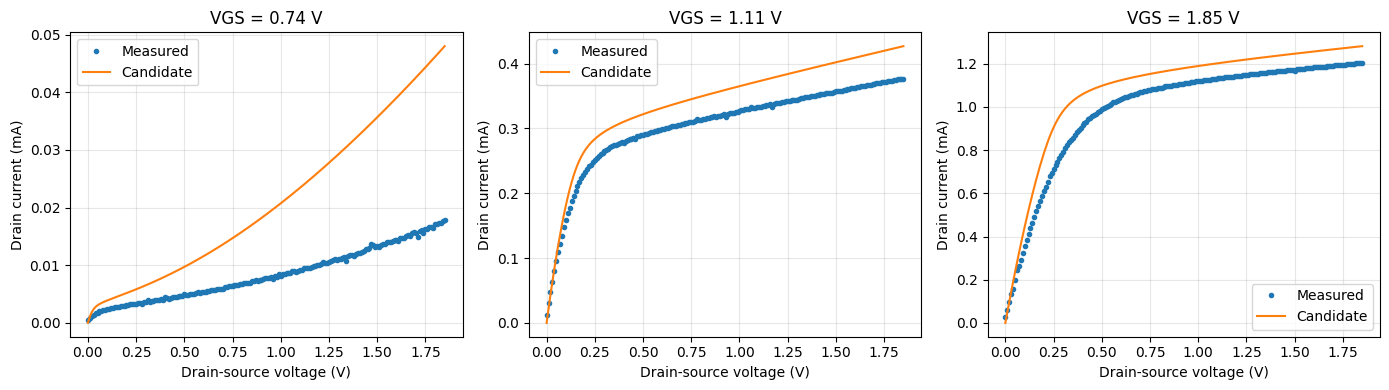

,VGS_V,Points,RMSE_uA,MAPE_pct
0,0.74,181,15.666736,133.430142
1,1.11,181,38.564276,12.156964
2,1.85,181,99.401531,10.490026


In [102]:
# 固定当前候选，比较三个训练栅压下的输出曲线
calibration_pm3.write_text(
    ".param cal_dvth=-0.150 cal_mu=0.25 cal_dn=0 cal_deta=-0.02\n"
    + eta_text
)

output_rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, vgs, tag in zip(
    axes, [0.74, 1.11, 1.85], ["0p74", "1p11", "1p85"]
):
    test_text, count = re.subn(
        r"(?im)^\s*VG\s+g\s+0\s+[^\n]+$",
        f"VG g 0 {vgs}",
        output_text
    )
    assert count == 1

    test_circuit = pdk_repo / "training_output_test.cir"
    test_circuit.write_text(test_text)
    output_file.unlink(missing_ok=True)

    run = subprocess.run(
        ["ngspice", "-b", test_circuit.name],
        cwd=str(pdk_repo), capture_output=True, text=True
    )
    assert run.returncode == 0, run.stdout + run.stderr
    assert output_file.exists()

    scan = np.loadtxt(output_file, skiprows=1)
    assert scan.ndim == 2 and len(scan) == 186
    assert np.all(np.isfinite(scan))
    assert np.all(np.diff(scan[:, 1]) > 0)

    data = pd.read_csv(
        repo / f"cryo_data/nmos_FET_len_0p15_wid_1p6/idvd_Vg{tag}.csv",
        skipinitialspace=True
    )
    assert np.allclose(data["Vg_src"], vgs)

    vd = data["Vd_src"].to_numpy()
    measured = data["Id"].to_numpy()
    assert vd.min() >= scan[:, 1].min()
    assert vd.max() <= scan[:, 1].max()

    predicted = np.interp(vd, scan[:, 1], scan[:, -1])
    mask = (vd >= 0.05) & (measured > 0)
    assert mask.any()

    rmse = np.sqrt(np.mean(
        (predicted[mask] - measured[mask])**2
    )) * 1e6
    mape = np.mean(np.abs(
        predicted[mask] / measured[mask] - 1
    )) * 100

    output_rows.append([vgs, mask.sum(), rmse, mape])

    ax.plot(vd, measured * 1e3, ".", label="Measured")
    ax.plot(scan[:, 1], scan[:, -1] * 1e3, label="Candidate")
    ax.set_title(f"VGS = {vgs:.2f} V")
    ax.set_xlabel("Drain-source voltage (V)")
    ax.set_ylabel("Drain current (mA)")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

training_output_summary = pd.DataFrame(
    output_rows,
    columns=["VGS_V", "Points", "RMSE_uA", "MAPE_pct"]
)
display(training_output_summary)

In [103]:
from scipy.optimize import least_squares

# 构建五条训练曲线的仿真任务
training_tasks = []

for kind, bias, tag in [
    ("idvg", 0.01, "0p01"),
    ("idvg", 0.37, "0p37"),
    ("idvd", 0.74, "0p74"),
    ("idvd", 1.11, "1p11"),
    ("idvd", 1.85, "1p85")
]:
    fixed_name = "Vd" if kind == "idvg" else "Vg"
    filename = f"{kind}_{fixed_name}{tag}.csv"
    data = pd.read_csv(
        repo / "cryo_data/nmos_FET_len_0p15_wid_1p6" / filename,
        skipinitialspace=True
    )

    if kind == "idvg":
        template, count = re.subn(
            r"(?im)^\s*VD\s+d\s+0\s+[^\n]+$",
            f"VD d 0 {bias}", cal_netlist
        )
        x = data["Vg_src"].to_numpy()
        fixed = data["Vd_src"].to_numpy()
        vector = "v(g)"
    else:
        template, count = re.subn(
            r"(?im)^\s*VG\s+g\s+0\s+[^\n]+$",
            f"VG g 0 {bias}", output_text
        )
        x = data["Vd_src"].to_numpy()
        fixed = data["Vg_src"].to_numpy()
        vector = "v(d)"

    assert count == 1
    assert np.allclose(fixed, bias)
    y = data["Id"].to_numpy()

    template, count = re.subn(
        r"(?im)^\s*wrdata\s+[^\n]+$",
        f"wrdata joint_fit_result.txt {vector} idrain",
        template
    )
    assert count == 1

    # 转移曲线分别平衡亚阈值区和导通区
    if kind == "idvg":
        groups = [
            (y >= 1e-8) & (y < 1e-6),
            y >= 1e-6
        ]
    else:
        groups = [(x >= 0.05) & (y >= 1e-8)]

    assert all(mask.any() for mask in groups)
    training_tasks.append((filename, template, x, y, groups))

fit_circuit = pdk_repo / "joint_fit_test.cir"
fit_output = pdk_repo / "joint_fit_result.txt"


def evaluate_candidate(parameters, return_table=False):
    dv, mu, deta = parameters
    calibration_pm3.write_text(
        f".param cal_dvth={dv:.12g} cal_mu={mu:.12g} "
        f"cal_dn=0 cal_deta={deta:.12g}\n" + eta_text
    )

    residuals = []
    rows = []

    for filename, template, x, y, groups in training_tasks:
        fit_circuit.write_text(template)
        fit_output.unlink(missing_ok=True)
        run = subprocess.run(
            ["ngspice", "-b", fit_circuit.name],
            cwd=str(pdk_repo), capture_output=True, text=True
        )
        if run.returncode != 0 or not fit_output.exists():
            raise RuntimeError(run.stdout + run.stderr)

        scan = np.loadtxt(fit_output, skiprows=1)
        assert scan.ndim == 2 and len(scan) == 186
        assert np.all(np.isfinite(scan))
        assert np.all(np.diff(scan[:, 1]) > 0)
        assert x.min() >= scan[:, 1].min()
        assert x.max() <= scan[:, 1].max()

        pred = np.interp(x, scan[:, 1], scan[:, -1])

        for mask in groups:
            # 极小或负预测电流给予很大的对数误差
            error = (
                np.log10(np.maximum(pred[mask], 1e-30))
                - np.log10(y[mask])
            )
            residuals.extend(
                error / np.sqrt(mask.sum() * len(groups))
            )

        mask = groups[-1]
        rmse = np.sqrt(np.mean((pred[mask] - y[mask])**2)) * 1e6
        mape = np.mean(np.abs(pred[mask] / y[mask] - 1)) * 100
        sub_error = np.nan
        if len(groups) == 2:
            sub_mask = groups[0]
            sub_error = np.sqrt(np.mean((
                np.log10(np.maximum(pred[sub_mask], 1e-30))
                - np.log10(y[sub_mask])
            )**2))

        rows.append([filename, rmse, mape, sub_error])

    if return_table:
        return pd.DataFrame(
            rows,
            columns=["file", "RMSE_uA", "MAPE_pct",
                     "Sub_log_RMSE_dec"]
        )
    return np.asarray(residuals)


# 发生错误时恢复运行前的模型文件
previous_model_text = calibration_pm3.read_text()

try:
    fit = least_squares(
        evaluate_candidate,
        x0=[-0.150, 0.25, -0.02],
        bounds=([-0.25, 0.05, -0.20], [-0.05, 1.0, 0.10]),
        x_scale=[0.1, 0.25, 0.05],
        diff_step=1e-3,
        max_nfev=40,
        verbose=1
    )

    joint_training_summary = evaluate_candidate(
        fit.x, return_table=True
    )

    print("优化状态：", fit.message)
    print("Δvth0 =", fit.x[0], "V")
    print("mu_scale =", fit.x[1])
    print("Δeta0 =", fit.x[2])
    display(joint_training_summary)

except Exception:
    calibration_pm3.write_text(previous_model_text)
    raise

`ftol` termination condition is satisfied.
Function evaluations 9, initial cost 9.8071e-02, final cost 2.4269e-02, first-order optimality 1.87e-05.
优化状态： `ftol` termination condition is satisfied.
Δvth0 = -0.1649769593638255 V
mu_scale = 0.18650336763705863
Δeta0 = -0.06190935656263113


,file,RMSE_uA,MAPE_pct,Sub_log_RMSE_dec
0,idvg_Vd0p01.csv,8.305306,23.656228,0.136901
1,idvg_Vd0p37.csv,24.908584,9.980230,0.151656
2,idvd_Vg0p74.csv,1.647402,27.781773,NaN
3,idvd_Vg1p11.csv,24.390781,6.153776,NaN
4,idvd_Vg1p85.csv,39.774801,3.657178,NaN


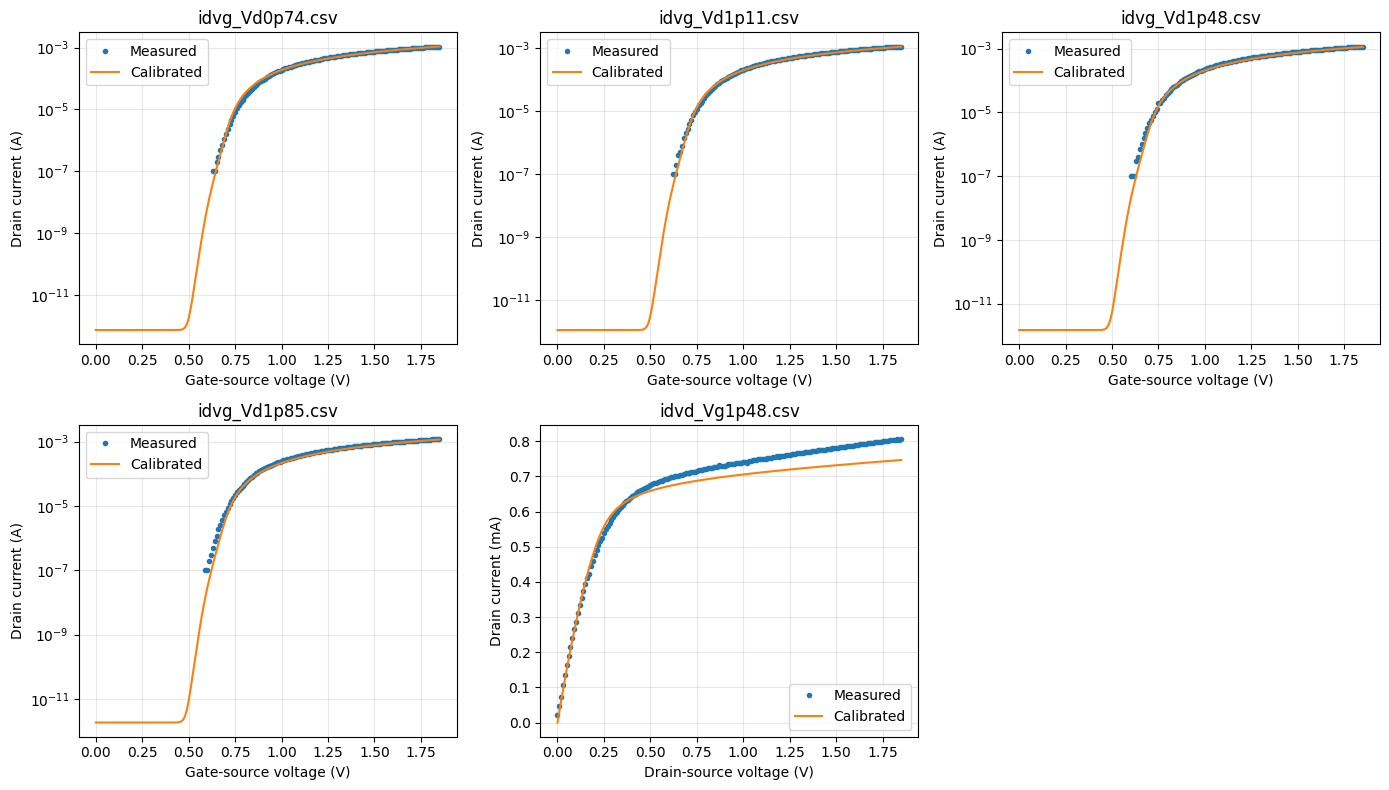

,file,Points,RMSE_uA,MAPE_pct,Sub_log_RMSE_dec
0,idvg_Vd0p74.csv,117,18.364485,6.414855,0.207753
1,idvg_Vd1p11.csv,118,27.313901,6.191137,0.269662
2,idvg_Vd1p48.csv,120,36.281428,8.124263,0.470062
3,idvg_Vd1p85.csv,121,45.354664,11.552061,0.594033
4,idvd_Vg1p48.csv,181,36.576026,4.478606,NaN


In [104]:
# 使用刚才拟合得到的参数，保持模型不变
assert np.all(np.isfinite(fit.x))
dv, mu, deta = fit.x

calibration_pm3.write_text(
    f".param cal_dvth={dv:.12g} cal_mu={mu:.12g} "
    f"cal_dn=0 cal_deta={deta:.12g}\n" + eta_text
)

validation_rows = []
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

validation_specs = [
    ("idvg", 0.74, "0p74"),
    ("idvg", 1.11, "1p11"),
    ("idvg", 1.48, "1p48"),
    ("idvg", 1.85, "1p85"),
    ("idvd", 1.48, "1p48")
]

for ax, (kind, bias, tag) in zip(axes.flat, validation_specs):
    fixed_name = "Vd" if kind == "idvg" else "Vg"
    filename = f"{kind}_{fixed_name}{tag}.csv"
    data = pd.read_csv(
        repo / "cryo_data/nmos_FET_len_0p15_wid_1p6" / filename,
        skipinitialspace=True
    )

    if kind == "idvg":
        template, count = re.subn(
            r"(?im)^\s*VD\s+d\s+0\s+[^\n]+$",
            f"VD d 0 {bias}", cal_netlist
        )
        x = data["Vg_src"].to_numpy()
        assert np.allclose(data["Vd_src"], bias)
        vector = "v(g)"
        xlabel = "Gate-source voltage (V)"
    else:
        template, count = re.subn(
            r"(?im)^\s*VG\s+g\s+0\s+[^\n]+$",
            f"VG g 0 {bias}", output_text
        )
        x = data["Vd_src"].to_numpy()
        assert np.allclose(data["Vg_src"], bias)
        vector = "v(d)"
        xlabel = "Drain-source voltage (V)"

    assert count == 1

    template, count = re.subn(
        r"(?im)^\s*wrdata\s+[^\n]+$",
        f"wrdata validation_result.txt {vector} idrain",
        template
    )
    assert count == 1

    circuit = pdk_repo / "validation_test.cir"
    result = pdk_repo / "validation_result.txt"
    circuit.write_text(template)
    result.unlink(missing_ok=True)

    run = subprocess.run(
        ["ngspice", "-b", circuit.name],
        cwd=str(pdk_repo), capture_output=True, text=True
    )
    assert run.returncode == 0, run.stdout + run.stderr
    assert result.exists()

    scan = np.loadtxt(result, skiprows=1)
    assert scan.ndim == 2 and len(scan) == 186
    assert np.all(np.isfinite(scan))
    assert np.all(np.diff(scan[:, 1]) > 0)
    assert x.min() >= scan[:, 1].min()
    assert x.max() <= scan[:, 1].max()

    measured = data["Id"].to_numpy()
    predicted = np.interp(x, scan[:, 1], scan[:, -1])

    if kind == "idvg":
        mask = measured >= 1e-6
        sub = (measured >= 1e-8) & (measured < 1e-6)
        assert sub.any() and np.all(predicted[sub] > 0)
        log_rmse = np.sqrt(np.mean(
            (np.log10(predicted[sub])
             - np.log10(measured[sub]))**2
        ))
        positive = measured > 0
        ax.semilogy(x[positive], measured[positive], ".",
                    label="Measured")
        ax.semilogy(scan[:, 1], scan[:, -1], label="Calibrated")
        ax.set_ylabel("Drain current (A)")
    else:
        mask = (x >= 0.05) & (measured > 0)
        log_rmse = np.nan
        ax.plot(x, measured * 1e3, ".", label="Measured")
        ax.plot(scan[:, 1], scan[:, -1] * 1e3,
                label="Calibrated")
        ax.set_ylabel("Drain current (mA)")

    assert mask.any()
    rmse = np.sqrt(np.mean(
        (predicted[mask] - measured[mask])**2
    )) * 1e6
    mape = np.mean(np.abs(
        predicted[mask] / measured[mask] - 1
    )) * 100

    validation_rows.append([
        filename, int(mask.sum()), rmse, mape, log_rmse
    ])

    ax.set_title(filename)
    ax.set_xlabel(xlabel)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

validation_summary = pd.DataFrame(
    validation_rows,
    columns=["file", "Points", "RMSE_uA",
             "MAPE_pct", "Sub_log_RMSE_dec"]
)
display(validation_summary)

In [105]:
import json
import shutil

checkpoint = repo / "my_77k_calibration_checkpoint"
checkpoint.mkdir(parents=True, exist_ok=True)

parameters = {
    "delta_vth0_V": float(fit.x[0]),
    "mu_scale": float(fit.x[1]),
    "delta_eta0": float(fit.x[2]),
    "delta_nfactor": 0.0,
    "temperature_K": 77,
    "L_um": 0.15,
    "W_um": 1.6,
    "VBS_V": 0.0,
    "status": "Frozen three-parameter candidate; holdout evaluated"
}

(checkpoint / "parameters.json").write_text(
    json.dumps(parameters, indent=2),
    encoding="utf-8"
)

joint_training_summary.to_csv(
    checkpoint / "training_errors.csv", index=False
)
validation_summary.to_csv(
    checkpoint / "holdout_errors.csv", index=False
)

# 保存完整 PDK 目录及当前校准文件，保留依赖和版本信息。
# 这是当前 Colab 工作目录的快照，不是可移植发布包。
shutil.copytree(
    pdk_repo,
    checkpoint / "pdk_snapshot",
    dirs_exist_ok=True
)

archive = shutil.make_archive(
    str(repo / "my_77k_calibration_checkpoint"),
    "zip",
    root_dir=str(checkpoint)
)

print("已保存：", archive)

from google.colab import files
files.download(archive)

已保存： /content/sky130_77k/my_77k_calibration_checkpoint.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [106]:
import re
import subprocess
import numpy as np
import pandas as pd

# 1. 固定已经验证过的校准参数，不重新优化
frozen_parameters = {
    "dvth": -0.1649769593638255,
    "mu": 0.18650336763705863,
    "deta": -0.06190935656263113
}

calibration_pm3.write_text(
    f".param cal_dvth={frozen_parameters['dvth']:.12g} "
    f"cal_mu={frozen_parameters['mu']:.12g} "
    f"cal_dn=0 cal_deta={frozen_parameters['deta']:.12g}\n"
    + eta_text
)

# 2. 三套模型的入口文件和运行目录
author_model = (
    repo / "cryo_models"
    / "sky130_fd_pr__nfet_01v8_lvt__tt_77k.corner.spice"
)

models = [
    ("Original_TT", minimal_path, pdk_repo),
    ("Author_77K", author_model, repo),
    ("My_77K", cal_loader, pdk_repo)
]

for name, loader, workdir in models:
    assert loader.exists(), f"{name} 模型入口不存在：{loader}"

data_dir = repo / "cryo_data/nmos_FET_len_0p15_wid_1p6"
results_dir = repo / "three_model_comparison"
results_dir.mkdir(parents=True, exist_ok=True)

# 3. 保持之前划分的训练／留出曲线
specs = [
    ("idvg", 0.01, "0p01", "fit"),
    ("idvg", 0.37, "0p37", "fit"),
    ("idvg", 0.74, "0p74", "check"),
    ("idvg", 1.11, "1p11", "check"),
    ("idvg", 1.48, "1p48", "check"),
    ("idvg", 1.85, "1p85", "check"),
    ("idvd", 0.74, "0p74", "fit"),
    ("idvd", 1.11, "1p11", "fit"),
    ("idvd", 1.48, "1p48", "check"),
    ("idvd", 1.85, "1p85", "fit")
]

comparison_rows = []

# 4. 每条曲线分别运行三套模型
for kind, bias, tag, role in specs:
    fixed_name = "Vd" if kind == "idvg" else "Vg"
    filename = f"{kind}_{fixed_name}{tag}.csv"
    data = pd.read_csv(data_dir / filename, skipinitialspace=True)

    if kind == "idvg":
        x = data["Vg_src"].to_numpy()
        assert np.allclose(data["Vd_src"], bias)
        vd_value, vg_value = bias, 0
        sweep = "dc VG 0 1.85 0.01"
        vector = "v(g)"
    else:
        x = data["Vd_src"].to_numpy()
        assert np.allclose(data["Vg_src"], bias)
        vd_value, vg_value = 0, bias
        sweep = "dc VD 0 1.85 0.01"
        vector = "v(d)"

    measured = data["Id"].to_numpy()
    assert np.all(np.isfinite(x))
    assert np.all(np.isfinite(measured))

    for model_name, loader, workdir in models:
        circuit = workdir / "three_model_test.cir"
        result = workdir / "three_model_result.txt"

        circuit.write_text("\n".join([
            "Three-model comparison at 77 K",
            f'.include "{loader.resolve()}"',
            ".option scale=1u",
            ".param mc_mm_switch=0 mc_pr_switch=0",
            ".temp -196.15",
            f"VD d 0 {vd_value}",
            f"VG g 0 {vg_value}",
            "X1 d g 0 0 sky130_fd_pr__nfet_01v8_lvt l=0.15 w=1.6",
            ".control",
            "set wr_singlescale",
            "set wr_vecnames",
            sweep,
            "let idrain = -i(VD)",
            f"wrdata three_model_result.txt {vector} idrain",
            "quit",
            ".endc",
            ".end",
            ""
        ]))

        result.unlink(missing_ok=True)
        run = subprocess.run(
            ["ngspice", "-b", circuit.name],
            cwd=str(workdir), capture_output=True, text=True
        )
        assert run.returncode == 0, (
            f"{model_name}, {filename}\n" + run.stdout + run.stderr
        )
        assert result.exists()

        scan = np.loadtxt(result, skiprows=1)
        assert scan.ndim == 2 and len(scan) == 186
        assert np.all(np.isfinite(scan))
        assert np.all(np.diff(scan[:, 1]) > 0)
        assert x.min() >= scan[:, 1].min()
        assert x.max() <= scan[:, 1].max()

        predicted = np.interp(x, scan[:, 1], scan[:, -1])

        # 所有模型统一按实测电流确定统计区间
        if kind == "idvg":
            mask = measured >= 1e-6
            sub = (measured >= 1e-8) & (measured < 1e-6)
            assert sub.any() and np.all(predicted[sub] > 0)
            sub_rmse = np.sqrt(np.mean(
                (np.log10(predicted[sub])
                 - np.log10(measured[sub]))**2
            ))
            sub_points = int(sub.sum())
        else:
            mask = (x >= 0.05) & (measured > 0)
            sub_rmse = np.nan
            sub_points = 0

        assert mask.any()
        rmse = np.sqrt(np.mean(
            (predicted[mask] - measured[mask])**2
        )) * 1e6
        mape = np.mean(np.abs(
            predicted[mask] / measured[mask] - 1
        )) * 100

        comparison_rows.append([
            filename, role, model_name, int(mask.sum()),
            rmse, mape, sub_points, sub_rmse
        ])

        # 保存每个模型的逐点预测，便于复查和画图
        pd.DataFrame({
            "sweep_V": x,
            "measured_Id_A": measured,
            "predicted_Id_A": predicted
        }).to_csv(
            results_dir / f"{filename[:-4]}__{model_name}.csv",
            index=False
        )

    print("完成：", filename)

# 5. 保存完整误差表
three_model_summary = pd.DataFrame(
    comparison_rows,
    columns=[
        "file", "role", "model", "Points",
        "RMSE_uA", "MAPE_pct",
        "Sub_points", "Sub_log_RMSE_dec"
    ]
)
three_model_summary.to_csv(
    results_dir / "three_model_errors.csv", index=False
)

# 6. 显示留出曲线的对照结果
holdout = three_model_summary.query("role == 'check'")

print("\n留出曲线：平均绝对相对误差（%）")
display(holdout.pivot(
    index="file", columns="model", values="MAPE_pct"
).round(3))

print("\n留出转移曲线：亚阈值对数 RMSE（dec）")
display(
    holdout[holdout["Sub_points"] > 0].pivot(
        index="file", columns="model", values="Sub_log_RMSE_dec"
    ).round(3)
)

print("\n完整结果已保存到：", results_dir)

完成： idvg_Vd0p01.csv
完成： idvg_Vd0p37.csv
完成： idvg_Vd0p74.csv
完成： idvg_Vd1p11.csv
完成： idvg_Vd1p48.csv
完成： idvg_Vd1p85.csv
完成： idvd_Vg0p74.csv
完成： idvd_Vg1p11.csv
完成： idvd_Vg1p48.csv
完成： idvd_Vg1p85.csv

留出曲线：平均绝对相对误差（%）


model,Author_77K,My_77K,Original_TT
file,,,
idvd_Vg1p48.csv,1.357,4.479,8.494
idvg_Vd0p74.csv,9.317,6.415,18.191
idvg_Vd1p11.csv,7.107,6.191,15.044
idvg_Vd1p48.csv,5.347,8.124,14.374
idvg_Vd1p85.csv,4.607,11.552,14.067



留出转移曲线：亚阈值对数 RMSE（dec）


model,Author_77K,My_77K,Original_TT
file,,,
idvg_Vd0p74.csv,0.089,0.208,3.454
idvg_Vd1p11.csv,0.102,0.270,2.847
idvg_Vd1p48.csv,0.120,0.470,2.532
idvg_Vd1p85.csv,0.083,0.594,2.011



完整结果已保存到： /content/sky130_77k/three_model_comparison


In [107]:
import subprocess
import numpy as np
import pandas as pd

VDD = 1.8
VOUT_Q = 0.9
ID_Q = 100e-6
RD = (VDD - VOUT_Q) / ID_Q

amplifier_dir = repo / "common_source_amplifier"
amplifier_dir.mkdir(parents=True, exist_ok=True)

bias_rows = []

for model_name, loader, workdir in models:
    circuit = workdir / "amplifier_bias_search.cir"
    result = workdir / "amplifier_bias_search.txt"

    # 固定漏压，扫描栅压，寻找目标电流对应的栅压
    circuit.write_text("\n".join([
        f"Bias search: {model_name} at 77 K",
        f'.include "{loader.resolve()}"',
        ".option scale=1u",
        ".param mc_mm_switch=0 mc_pr_switch=0",
        ".temp -196.15",
        f"VD d 0 {VOUT_Q}",
        "VG g 0 0",
        "X1 d g 0 0 sky130_fd_pr__nfet_01v8_lvt l=0.15 w=1.6",
        ".control",
        "set wr_singlescale",
        "set wr_vecnames",
        "dc VG 0 1.8 0.001",
        "let idrain = -i(VD)",
        "wrdata amplifier_bias_search.txt v(g) idrain",
        "quit",
        ".endc",
        ".end",
        ""
    ]))

    result.unlink(missing_ok=True)
    run = subprocess.run(
        ["ngspice", "-b", circuit.name],
        cwd=str(workdir), capture_output=True, text=True
    )
    assert run.returncode == 0, run.stdout + run.stderr
    assert result.exists()

    scan = np.loadtxt(result, skiprows=1)
    assert scan.ndim == 2 and len(scan) == 1801
    assert np.all(np.isfinite(scan))

    vg = scan[:, 1]
    current = scan[:, -1]
    assert np.all(np.diff(vg) > 0)

    # 找到电流从目标值下方跨到上方的位置
    crossings = np.flatnonzero(
        (current[:-1] <= ID_Q) & (current[1:] > ID_Q)
    )
    assert len(crossings) == 1, (
        f"{model_name}：未找到唯一的 100 uA 交点"
    )

    k = crossings[0]
    gate_bias = vg[k] + (
        (ID_Q - current[k])
        / (current[k + 1] - current[k])
        * (vg[k + 1] - vg[k])
    )

    bias_rows.append([
        model_name, VDD, RD, VOUT_Q, ID_Q * 1e6, gate_bias
    ])

    pd.DataFrame({
        "VGS_V": vg,
        "Id_A": current
    }).to_csv(
        amplifier_dir / f"{model_name}_bias_search.csv",
        index=False
    )

    # 保存这一模型的扫描网表
    (amplifier_dir / f"{model_name}_bias_search.cir").write_text(
        circuit.read_text()
    )

bias_summary = pd.DataFrame(
    bias_rows,
    columns=[
        "model", "VDD_V", "RD_ohm",
        "target_Vout_V", "target_Id_uA", "required_VG_V"
    ]
)

reference_vg = bias_summary.loc[
    bias_summary["model"] == "Original_TT", "required_VG_V"
].iloc[0]

bias_summary["VG_shift_vs_original_mV"] = (
    bias_summary["required_VG_V"] - reference_vg
) * 1000

bias_summary.to_csv(
    amplifier_dir / "required_gate_bias.csv",
    index=False
)

print("漏极电阻 RD =", RD, "ohm")
display(bias_summary)

漏极电阻 RD = 9000.0 ohm


,model,VDD_V,RD_ohm,target_Vout_V,target_Id_uA,required_VG_V,VG_shift_vs_original_mV
0,Original_TT,1.8,9000.0,0.9,100.0,0.922603,0.000000
1,Author_77K,1.8,9000.0,0.9,100.0,0.874552,-48.051167
2,My_77K,1.8,9000.0,0.9,100.0,0.895968,-26.635699


In [108]:
# 使用表中未四舍五入的栅压
original_vg = float(
    bias_summary.loc[
        bias_summary["model"] == "Original_TT", "required_VG_V"
    ].iloc[0]
)

amplifier_rows = []

for mode in ["Fixed_VG", "Retuned_VG"]:
    for model_name, loader, workdir in models:
        own_vg = float(
            bias_summary.loc[
                bias_summary["model"] == model_name, "required_VG_V"
            ].iloc[0]
        )
        gate_voltage = original_vg if mode == "Fixed_VG" else own_vg

        circuit = workdir / "common_source_test.cir"
        op_file = workdir / "common_source_op.txt"
        ac_file = workdir / "common_source_ac.txt"

        circuit_text = "\n".join([
            f"Common-source amplifier: {mode}, {model_name}",
            f'.include "{loader.resolve()}"',
            ".option scale=1u",
            ".param mc_mm_switch=0 mc_pr_switch=0",
            ".temp -196.15",
            f"VDD supply 0 {VDD}",
            f"RD supply out {RD}",
            f"VG g 0 DC {gate_voltage:.12g} AC 1",
            "X1 out g 0 0 sky130_fd_pr__nfet_01v8_lvt l=0.15 w=1.6",
            ".control",
            "set wr_singlescale",
            "set wr_vecnames",
            "op",
            "let supply_current = -i(VDD)",
            "wrdata common_source_op.txt v(g) v(out) supply_current",
            "ac lin 3 1 10",
            "let gain_real = real(v(out)/v(g))",
            "let gain_imag = imag(v(out)/v(g))",
            "wrdata common_source_ac.txt gain_real gain_imag",
            "quit",
            ".endc",
            ".end",
            ""
        ])

        circuit.write_text(circuit_text)
        op_file.unlink(missing_ok=True)
        ac_file.unlink(missing_ok=True)

        run = subprocess.run(
            ["ngspice", "-b", circuit.name],
            cwd=str(workdir), capture_output=True, text=True
        )
        assert run.returncode == 0, run.stdout + run.stderr
        assert op_file.exists() and ac_file.exists()

        op_data = np.loadtxt(op_file, skiprows=1, ndmin=2)
        ac_data = np.loadtxt(ac_file, skiprows=1, ndmin=2)
        assert op_data.shape == (1, 4), op_data.shape
        assert ac_data.shape == (3, 3), ac_data.shape
        assert np.all(np.isfinite(op_data))
        assert np.all(np.isfinite(ac_data))

        actual_vg, vout, supply_current = op_data[0, -3:]
        resistor_current = (VDD - vout) / RD

        # 检查电阻电流与电源提供的电流一致
        assert np.isclose(
            supply_current, resistor_current,
            rtol=1e-5, atol=1e-10
        )
        assert 0 < vout < VDD

        # 取 1 Hz 的小信号增益
        gain = complex(ac_data[0, 1], ac_data[0, 2])
        assert abs(gain) > 0
        gain_db = 20 * np.log10(abs(gain))
        phase_deg = np.angle(gain, deg=True)

        amplifier_rows.append([
            mode, model_name, actual_vg, vout,
            supply_current * 1e6,
            gain.real, gain_db, phase_deg
        ])

        # 保存每种条件的网表与原始结果
        prefix = amplifier_dir / f"{mode}__{model_name}"
        prefix.with_suffix(".cir").write_text(circuit_text)
        pd.DataFrame(
            op_data, columns=["scale", "VG_V", "Vout_V", "Isupply_A"]
        ).to_csv(str(prefix) + "_op.csv", index=False)
        pd.DataFrame(
            ac_data, columns=["frequency_Hz", "gain_real", "gain_imag"]
        ).to_csv(str(prefix) + "_ac.csv", index=False)

amplifier_summary = pd.DataFrame(
    amplifier_rows,
    columns=[
        "mode", "model", "VG_V", "Vout_V",
        "Isupply_uA", "Gain_real_V_V", "Gain_dB", "Phase_deg"
    ]
)

amplifier_summary.to_csv(
    amplifier_dir / "bias_and_gain_comparison.csv",
    index=False
)

display(amplifier_summary.round(6))

,mode,model,VG_V,Vout_V,Isupply_uA,Gain_real_V_V,Gain_dB,Phase_deg
0,Fixed_VG,Original_TT,0.922603,0.900001,99.999910,-5.727934,15.159960,180.0
1,Fixed_VG,Author_77K,0.922603,0.607094,132.545108,-5.730511,15.163867,180.0
2,Fixed_VG,My_77K,0.922603,0.736096,118.211515,-6.164026,15.797290,180.0
3,Retuned_VG,Original_TT,0.922603,0.900001,99.999910,-5.727934,15.159960,180.0
4,Retuned_VG,Author_77K,0.874552,0.900001,99.999845,-6.310463,16.001225,180.0
5,Retuned_VG,My_77K,0.895968,0.900000,99.999974,-6.114369,15.727032,180.0


In [109]:
gain_check_rows = []

for _, row in amplifier_summary.iterrows():
    mode = row["mode"]
    model_name = row["model"]
    gate_voltage = float(row["VG_V"])
    ac_gain = float(row["Gain_real_V_V"])

    _, loader, workdir = next(
        item for item in models if item[0] == model_name
    )

    for h in [1e-4, 5e-5]:
        circuit = workdir / "gain_dc_check.cir"
        result = workdir / "gain_dc_check.txt"

        circuit.write_text("\n".join([
            f"DC gain check: {mode}, {model_name}",
            f'.include "{loader.resolve()}"',
            ".option scale=1u",
            ".param mc_mm_switch=0 mc_pr_switch=0",
            ".temp -196.15",
            f"VDD supply 0 {VDD}",
            f"RD supply out {RD}",
            f"VG g 0 {gate_voltage:.12g}",
            "X1 out g 0 0 sky130_fd_pr__nfet_01v8_lvt l=0.15 w=1.6",
            ".control",
            "set wr_singlescale",
            "set wr_vecnames",
            f"dc VG {gate_voltage-h:.12g} "
            f"{gate_voltage+h:.12g} {h:.12g}",
            "wrdata gain_dc_check.txt v(g) v(out)",
            "quit",
            ".endc",
            ".end",
            ""
        ]))

        result.unlink(missing_ok=True)
        run = subprocess.run(
            ["ngspice", "-b", circuit.name],
            cwd=str(workdir), capture_output=True, text=True
        )
        assert run.returncode == 0, run.stdout + run.stderr
        assert result.exists()

        scan = np.loadtxt(result, skiprows=1, ndmin=2)
        assert scan.shape == (3, 3), scan.shape
        assert np.all(np.isfinite(scan))
        assert np.all(np.diff(scan[:, 1]) > 0)

        dc_gain = (
            (scan[-1, 2] - scan[0, 2])
            / (scan[-1, 1] - scan[0, 1])
        )
        difference_pct = abs(dc_gain - ac_gain) / abs(ac_gain) * 100

        gain_check_rows.append([
            mode, model_name, h * 1e3,
            ac_gain, dc_gain, difference_pct
        ])

gain_check_summary = pd.DataFrame(
    gain_check_rows,
    columns=[
        "mode", "model", "step_mV",
        "AC_gain_V_V", "DC_gain_V_V", "difference_pct"
    ]
)

gain_check_summary.to_csv(
    amplifier_dir / "gain_crosscheck.csv",
    index=False
)

display(gain_check_summary.round(6))

,mode,model,step_mV,AC_gain_V_V,DC_gain_V_V,difference_pct
0,Fixed_VG,Original_TT,0.10,-5.727934,-5.727935,0.000021
1,Fixed_VG,Original_TT,0.05,-5.727934,-5.727930,0.000066
2,Fixed_VG,Author_77K,0.10,-5.730511,-5.730485,0.000457
3,Fixed_VG,Author_77K,0.05,-5.730511,-5.730460,0.000893
4,Fixed_VG,My_77K,0.10,-6.164026,-6.164025,0.000021
5,Fixed_VG,My_77K,0.05,-6.164026,-6.164030,0.000061
6,Retuned_VG,Original_TT,0.10,-5.727934,-5.727935,0.000021
7,Retuned_VG,Original_TT,0.05,-5.727934,-5.727930,0.000066
8,Retuned_VG,Author_77K,0.10,-6.310463,-6.310460,0.000053
9,Retuned_VG,Author_77K,0.05,-6.310463,-6.310460,0.000053


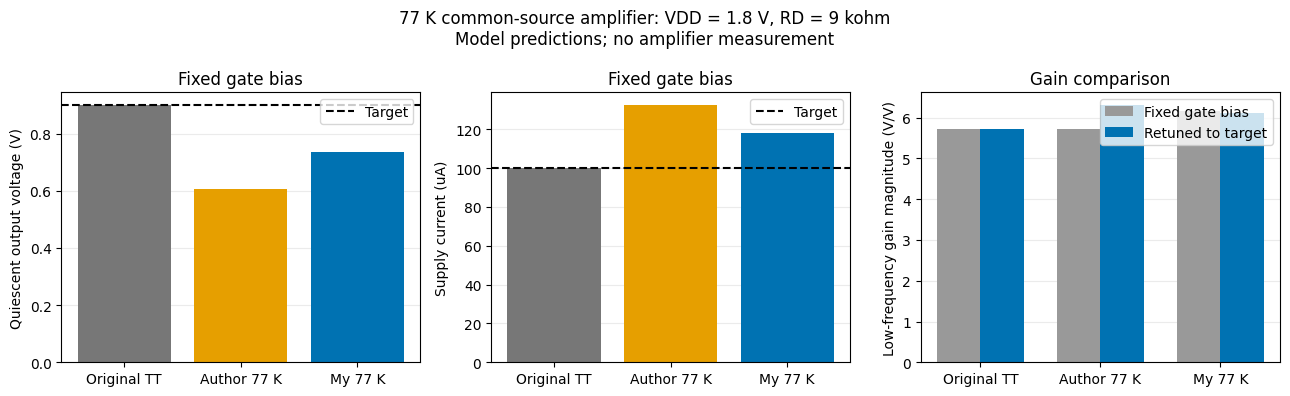

In [110]:
import matplotlib.pyplot as plt
import numpy as np

model_order = ["Original_TT", "Author_77K", "My_77K"]
labels = ["Original TT", "Author 77 K", "My 77 K"]
colors = ["#777777", "#E69F00", "#0072B2"]

fixed = (
    amplifier_summary.query("mode == 'Fixed_VG'")
    .set_index("model").loc[model_order]
)
retuned = (
    amplifier_summary.query("mode == 'Retuned_VG'")
    .set_index("model").loc[model_order]
)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].bar(labels, fixed["Vout_V"], color=colors)
axes[0].axhline(0.9, color="black", linestyle="--", label="Target")
axes[0].set_title("Fixed gate bias")
axes[0].set_ylabel("Quiescent output voltage (V)")
axes[0].legend()

axes[1].bar(labels, fixed["Isupply_uA"], color=colors)
axes[1].axhline(100, color="black", linestyle="--", label="Target")
axes[1].set_title("Fixed gate bias")
axes[1].set_ylabel("Supply current (uA)")
axes[1].legend()

x = np.arange(len(labels))
width = 0.36
axes[2].bar(
    x - width / 2, -fixed["Gain_real_V_V"],
    width, label="Fixed gate bias", color="#999999"
)
axes[2].bar(
    x + width / 2, -retuned["Gain_real_V_V"],
    width, label="Retuned to target", color="#0072B2"
)
axes[2].set_xticks(x, labels)
axes[2].set_ylabel("Low-frequency gain magnitude (V/V)")
axes[2].set_title("Gain comparison")
axes[2].legend()

for ax in axes:
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "77 K common-source amplifier: VDD = 1.8 V, RD = 9 kohm\n"
    "Model predictions; no amplifier measurement"
)
plt.tight_layout()

fig.savefig(
    amplifier_dir / "amplifier_comparison.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    amplifier_dir / "amplifier_comparison.svg",
    bbox_inches="tight"
)
plt.show()

In [111]:
from pathlib import Path
import re
import tempfile
import subprocess
import numpy as np
from google.colab import files

# 检查原来的校准模型入口
assert cal_loader.exists(), "校准模型入口不存在，请检查运行环境是否已重置"

# 将 .include 依赖递归展开成一个文件
include_pattern = re.compile(
    r"""^\s*\.include\s+(?:"([^"]+)"|'([^']+)'|(\S+))\s*(?:\*.*)?$""",
    re.I
)

def flatten_model(path, stack=()):
    path = Path(path).resolve()
    assert path.exists(), f"缺少依赖文件：{path}"
    assert path not in stack, f"发现循环引用：{path}"

    flattened = []
    for line in path.read_text().splitlines():
        match = include_pattern.match(line)
        if match:
            target = next(v for v in match.groups() if v is not None)
            dependency = Path(target)
            if not dependency.is_absolute():
                dependency = path.parent / dependency
            flattened.append(f"* BEGIN dependency: {dependency.name}")
            flattened.append(flatten_model(dependency, stack + (path,)))
            flattened.append(f"* END dependency: {dependency.name}")
        else:
            assert not re.match(r"^\s*\.include\b", line, re.I), (
                f"无法解析依赖行：{line}"
            )
            flattened.append(line)

    return "\n".join(flattened)

flat_text = flatten_model(cal_loader)

# 独立入口：固定尺寸，并保留四个外部端口
wrapper = """
* Fixed-geometry calibrated NMOS
* T = 77 K must be set in the simulation circuit.
* Model port order: drain gate source bulk
.subckt my77k_nmos d g s b
Xcore d g s b sky130_fd_pr__nfet_01v8_lvt l=0.15 w=1.6
.ends my77k_nmos
"""

portable_text = (
    "* Calibrated SKY130 low-Vt NMOS; fixed geometry\n"
    "* L=0.15 um, W=1.6 um; calibrated at 77 K\n"
    + flat_text + "\n" + wrapper
)

assert not re.search(r"^\s*\.include\b", portable_text, re.M | re.I)

# 在独立目录测试，确认不依赖 Colab 的原目录
with tempfile.TemporaryDirectory() as temporary:
    test_dir = Path(temporary)
    (test_dir / "my77k_nmos.lib").write_text(portable_text)

    (test_dir / "check.cir").write_text("""Portable model operating-point check
Portable model operating-point check
.include "my77k_nmos.lib"
.temp -196.15
VDD supply 0 1.8
RD supply out 9000
VG g 0 0.895968
X1 out g 0 0 my77k_nmos
.control
set wr_singlescale
set wr_vecnames
op
let isupply = -i(VDD)
wrdata check.txt v(out) isupply
quit
.endc
.end
""")

    run = subprocess.run(
        ["ngspice", "-b", "check.cir"],
        cwd=str(test_dir), capture_output=True, text=True
    )
    assert run.returncode == 0, run.stdout + run.stderr
    assert (test_dir / "check.txt").exists()

    result = np.loadtxt(
        test_dir / "check.txt", skiprows=1, ndmin=2
    )
    vout, current = result[0, -2:]
    print("独立模型检查：")
    print("Vout =", vout, "V")
    print("电源电流 =", current * 1e6, "uA")

    assert abs(vout - 0.9) < 0.005, "工作点不符，先不要导入 KiCad"
    assert abs(current - 100e-6) < 0.5e-6, "工作点不符，先不要导入 KiCad"

portable_path = Path("/content/my77k_nmos.lib")
portable_path.write_text(portable_text)
print("检查通过，下载：", portable_path.name)
files.download(str(portable_path))

AssertionError: 
Note: No compatibility mode selected!


Circuit: portable model operating-point check

warning, can't find model 'check' from line
    portable model operating-point check
Error on line 2 or its substitute:
  portable model operating-point check
Unable to find definition of model check
    Simulation interrupted due to error!

Note: No ".plot", ".print", or ".fourier" lines; no simulations run


In [113]:
from pathlib import Path
import tempfile
import subprocess
import numpy as np
from google.colab import files

assert "portable_text" in globals(), (
    "没有找到 portable_text，请先运行前面的模型合并单元"
)

# 删除可能混入模型文件的测试标题，保留真正的模型内容
clean_model_text = "\n".join(
    line for line in portable_text.splitlines()
    if line.strip().lower() != "portable model operating-point check"
)

with tempfile.TemporaryDirectory() as temporary:
    test_dir = Path(temporary)

    (test_dir / "my77k_nmos.lib").write_text(
        clean_model_text + "\n"
    )

    circuit_lines = [
        "* Portable model operating-point check",
        '.include "my77k_nmos.lib"',
        ".temp -196.15",
        "VDD supply 0 1.8",
        "RD supply out 9000",
        "VG g 0 0.895968",
        "X1 out g 0 0 my77k_nmos",
        ".control",
        "set wr_singlescale",
        "set wr_vecnames",
        "op",
        "let isupply = -i(VDD)",
        "wrdata check.txt v(out) isupply",
        "quit",
        ".endc",
        ".end"
    ]

    circuit_path = test_dir / "check.cir"
    circuit_path.write_text("\n".join(circuit_lines) + "\n")

    print("实际测试网表：")
    print(circuit_path.read_text())

    run = subprocess.run(
        ["ngspice", "-b", circuit_path.name],
        cwd=str(test_dir),
        capture_output=True,
        text=True
    )

    print("退出码：", run.returncode)
    print(run.stdout)
    print(run.stderr)

    assert run.returncode == 0, "仿真失败，请把上面的日志发来"

    result_path = test_dir / "check.txt"
    assert result_path.exists(), "没有生成工作点结果"

    result = np.loadtxt(result_path, skiprows=1, ndmin=2)
    assert np.all(np.isfinite(result))

    vout, current = result[0, -2:]
    print("Vout =", vout, "V")
    print("电源电流 =", current * 1e6, "uA")

    assert abs(vout - 0.9) < 0.005, (
        "输出电压与原结果不符，暂不导出"
    )
    assert abs(current - 100e-6) < 0.5e-6, (
        "电流与原结果不符，暂不导出"
    )

portable_path = Path("/content/my77k_nmos.lib")
portable_path.write_text(clean_model_text + "\n")

print("独立模型检查通过，开始下载 my77k_nmos.lib")
files.download(str(portable_path))

实际测试网表：
* Portable model operating-point check
.include "my77k_nmos.lib"
.temp -196.15
VDD supply 0 1.8
RD supply out 9000
VG g 0 0.895968
X1 out g 0 0 my77k_nmos
.control
set wr_singlescale
set wr_vecnames
op
let isupply = -i(VDD)
wrdata check.txt v(out) isupply
quit
.endc
.end

退出码： 0

Note: No compatibility mode selected!


Circuit: * portable model operating-point check

Doing analysis at TEMP = -196.150000 and TNOM = 27.000000


No. of Data Rows : 1
ngspice-42 done

Using SPARSE 1.3 as Direct Linear Solver

Vout = 0.899998092 V
电源电流 = 100.000212 uA
独立模型检查通过，开始下载 my77k_nmos.lib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [114]:
from pathlib import Path

model_path = Path("/content/my77k_nmos.lib")
assert model_path.exists(), "找不到导出的模型文件"

lines = model_path.read_text().splitlines()
error_line = 15382

print("模型总行数：", len(lines))
print("报错位置附近：")

for number in range(
    max(1, error_line - 6),
    min(len(lines), error_line + 6) + 1
):
    print(f"{number}: {lines[number - 1]}")

模型总行数： 24405
报错位置附近：
15376: + ub = 1.344944324e-18 lub = 1.742905241e-25 wub = 1.252797190e-24 pub = -1.953737218e-31
15377: + uc = -6.738595665e-11 luc = 1.532084359e-17 wuc = 1.774818658e-16 puc = -2.767829697e-23
15378: + rdsw = 103.65
15379: + prwb = 0.0
15380: + prwg = 0.0
15381: + wr = 1.0
15382: + u0 = (4.308038042e-02 * cal_mu) lu0 = (-4.480159737e-09 * cal_mu) wu0 = (-3.800182135e-08 * cal_mu) pu0 = (5.926384040e-15 * cal_mu)
15383: + a0 = 0.0
15384: + keta = 1.280836202e+00 lketa = -2.157926049e-07 wketa = -1.721292615e-06 pketa = 2.684355833e-13
15385: + a1 = 0.0
15386: + a2 = 0.38689047
15387: + ags = 4.427778610e-01 lags = 1.016360676e-07 wags = 1.565556175e-08 pags = -2.441484855e-15
15388: + b0 = 0.0


In [115]:
from pathlib import Path
import re
import shutil
import subprocess
import tempfile
import numpy as np

source = Path("/content/my77k_nmos.lib")
assert source.exists(), f"找不到文件：{source}"

text = source.read_text()

# 只修改我们引入的五个参数表达式
pattern = (
    r"\b(u0|lu0|wu0|pu0|eta0)"
    r"\s*=\s*\(([^()\r\n]+)\)"
)

fixed_text, count = re.subn(
    pattern,
    lambda m: f"{m.group(1)} = {{{m.group(2)}}}",
    text,
    flags=re.I
)

assert count == 5, f"预期修改 5 处，实际修改 {count} 处，请先停止"

# 保存新文件，保留原文件
fixed_path = source.with_name("my77k_nmos_kicad.lib")
fixed_path.write_text(fixed_text)

print("已修改：", count, "处")
print("新文件：", fixed_path)

# 再检查修改后是否保持原来的工作点
ngspice = shutil.which("ngspice")
assert ngspice is not None, "当前环境没有找到 ngspice"

with tempfile.TemporaryDirectory() as temporary:
    test_dir = Path(temporary)
    (test_dir / "model.lib").write_text(fixed_text)

    circuit = "\n".join([
        "* Check corrected model syntax",
        '.include "model.lib"',
        ".temp -196.15",
        "VDD supply 0 1.8",
        "RD supply out 9000",
        "VG g 0 0.895968",
        "X1 out g 0 0 my77k_nmos",
        ".control",
        "set wr_singlescale",
        "set wr_vecnames",
        "op",
        "let isupply = -i(VDD)",
        "wrdata check.txt v(out) isupply",
        "quit",
        ".endc",
        ".end",
        ""
    ])
    (test_dir / "check.cir").write_text(circuit)

    run = subprocess.run(
        [ngspice, "-b", "check.cir"],
        cwd=str(test_dir),
        capture_output=True,
        text=True
    )
    assert run.returncode == 0, run.stdout + run.stderr
    assert (test_dir / "check.txt").exists()

    result = np.loadtxt(
        test_dir / "check.txt", skiprows=1, ndmin=2
    )
    assert np.all(np.isfinite(result))
    vout, current = result[0, -2:]

    print("Vout =", vout, "V")
    print("电源电流 =", current * 1e6, "uA")

    assert abs(vout - 0.9) < 0.005
    assert abs(current - 100e-6) < 0.5e-6

print("工作点检查通过")

已修改： 5 处
新文件： /content/my77k_nmos_kicad.lib
Vout = 0.899998092 V
电源电流 = 100.000212 uA
工作点检查通过


In [116]:
from google.colab import files
files.download("/content/my77k_nmos_kicad.lib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [118]:
from pathlib import Path
import shutil
import zipfile
from datetime import datetime
from google.colab import files

data_repo = Path("/content/sky130_77k")
pdk_folder = Path("/content/sky130_fd_pr_original")

assert data_repo.exists(), (
    "原来的数据目录不存在，运行环境可能已经重置。"
    "请先停止，使用之前下载的 ZIP 恢复。"
)
assert pdk_folder.exists(), (
    "原来的模型目录不存在，运行环境可能已经重置。"
    "请先停止，使用之前下载的 ZIP 恢复。"
)

# 创建新的交付目录，不改动原数据
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
delivery = Path("/content") / f"SKY130_77K_delivery_{stamp}"
delivery.mkdir()

# 1. 收集全部 11 份实测 CSV
raw_dir = delivery / "data"
raw_dir.mkdir()

device_dir = (
    data_repo / "cryo_data/nmos_FET_len_0p15_wid_1p6"
)
raw_files = sorted(device_dir.glob("*.csv"))
assert len(raw_files) == 11, f"预期 11 份 CSV，实际找到 {len(raw_files)}"

for path in raw_files:
    shutil.copy2(path, raw_dir / path.name)

# 2. 保存仍在内存中的结果表，不重新计算
tables_dir = delivery / "tables"
tables_dir.mkdir()

table_variables = {
    "inventory": "data_inventory.csv",
    "parameter_table": "77K_device_parameters.csv",
    "joint_training_summary": "training_errors.csv",
    "validation_summary": "holdout_errors.csv",
    "three_model_summary": "three_model_errors.csv",
    "bias_summary": "required_gate_bias.csv",
    "amplifier_summary": "bias_and_gain_comparison.csv",
    "gain_check_summary": "gain_crosscheck.csv"
}

for variable, filename in table_variables.items():
    table = globals().get(variable)
    if table is not None and hasattr(table, "to_csv"):
        table.to_csv(tables_dir / filename, index=False)

# 3. 收集之前已经保存到磁盘的表格和图片
figures_dir = delivery / "figures"
figures_dir.mkdir()

for root in [data_repo, pdk_folder]:
    for path in sorted(root.rglob("*")):
        if not path.is_file():
            continue

        relative = path.relative_to(root)
        if any(part in {
            ".git", "__pycache__", "my_77k_calibration_checkpoint"
        } for part in relative.parts):
            continue

        # 保留目录关系，防止同名文件互相覆盖
        if path.suffix.lower() in {".png", ".svg", ".pdf"}:
            target = figures_dir / root.name / relative
        elif path.suffix.lower() == ".csv" and "cryo_data" not in relative.parts:
            target = tables_dir / root.name / relative
        else:
            continue

        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, target)

# 4. 备份模型、网表、依赖及原目录说明
# 保留目录结构；这一部分仍是备份，尚未保证所有网表路径可移植
backup_dir = delivery / "source_backup"
backup_dir.mkdir()

for root in [data_repo, pdk_folder]:
    for path in sorted(root.rglob("*")):
        if not path.is_file():
            continue

        relative = path.relative_to(root)
        if any(part in {
            ".git", "__pycache__", ".ipynb_checkpoints",
            "my_77k_calibration_checkpoint"
        } for part in relative.parts):
            continue
        if path.suffix.lower() == ".zip":
            continue

        target = backup_dir / root.name / relative
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, target)

# 5. 单独收集可用于 KiCad 的模型
models_dir = delivery / "models"
models_dir.mkdir()

portable_model = Path("/content/my77k_nmos_kicad.lib")
if portable_model.exists():
    shutil.copy2(portable_model, models_dir / portable_model.name)
else:
    print("待补：my77k_nmos_kicad.lib，请从 Mac 的 KiCad/models 文件夹复制。")

# 6. 打印哪些数值表已经找到
print("\n数值表检查：")
for filename in table_variables.values():
    matches = list(tables_dir.rglob(filename))
    print(("已找到：" if matches else "待补："), filename)

# 7. 压缩并下载
archive = delivery.with_suffix(".zip")
with zipfile.ZipFile(
    archive, "w", compression=zipfile.ZIP_DEFLATED
) as package:
    for path in sorted(delivery.rglob("*")):
        if path.is_file():
            package.write(path, path.relative_to(delivery))

print("\n已收集原始 CSV：", len(raw_files), "份")
print("Notebook 和 Mac 上的 KiCad 文件需要另外保存。")
print("压缩包：", archive.name)
files.download(str(archive))


数值表检查：
已找到： data_inventory.csv
已找到： 77K_device_parameters.csv
已找到： training_errors.csv
已找到： holdout_errors.csv
已找到： three_model_errors.csv
已找到： required_gate_bias.csv
已找到： bias_and_gain_comparison.csv
已找到： gain_crosscheck.csv

已收集原始 CSV： 11 份
Notebook 和 Mac 上的 KiCad 文件需要另外保存。
压缩包： SKY130_77K_delivery_20261123_054847.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [117]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df)

https://docs.google.com/spreadsheets/d/1w318qxSsVdwtQEUmwjIq_o7nUi1_ViQS-KSKEXdQt50/edit#gid=0
